# Transformer: Attention, Encoder, Decoder and Inference with Pretrained Models

The main objective of this project is to understand how Transformer models work, how attention mechanisms process text, and how pretrained language models perform tasks such as sentiment analysis, summarization, translation, and text generation.

For this project, I used Python, PyTorch, Hugging Face Transformers, NumPy, pandas, and Matplotlib.

I explored three important pretrained models: DistilBERT for sentiment analysis, GPT-2 for text generation, and T5-small for summarization and translation.

Instead of focusing only on theory, I implemented different experiments and visualized their outputs to understand the concepts practically.

# 1.1: Install and First Pipeline

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import pipeline
import torch

## Load pretrained sentiment model

In [3]:
torch.manual_seed(42)
np.random.seed(42)

# Plot settings
sns.set_theme(style="whitegrid")

In [4]:
model_name = "distilbert-base-uncased-finetuned-sst-2-english"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=model_name,
    device=-1 
)

print("Model loaded successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully!


## Create five sentences

In [5]:
sentences = [
    "I absolutely love learning deep learning.",
    "This movie was boring and disappointing.",
    "The food was excellent and delicious.",
    "I do not think this product is good.",
    "The movie was not bad, and I enjoyed it."
]

for sentence in sentences:
    print(sentence)

I absolutely love learning deep learning.
This movie was boring and disappointing.
The food was excellent and delicious.
I do not think this product is good.
The movie was not bad, and I enjoyed it.


## Predict sentiment and confidence score

In [6]:
results = sentiment_pipeline(sentences)

for i, (sentence, result) in enumerate(
    zip(sentences, results), start=1
):
    print(f"Sentence {i}: {sentence}")
    print("Predicted label:", result["label"])
    print("Confidence score:", round(result["score"], 4))
    print("-" * 70)

Sentence 1: I absolutely love learning deep learning.
Predicted label: POSITIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 2: This movie was boring and disappointing.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 3: The food was excellent and delicious.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------
Sentence 4: I do not think this product is good.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 5: The movie was not bad, and I enjoyed it.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------


## Display results in a table

In [7]:
df = pd.DataFrame({
    "Sentence": sentences,
    "Predicted Label": [result["label"] for result in results],
    "Confidence Score": [
        round(result["score"], 4) for result in results
    ]
})

display(df)

,Sentence,Predicted Label,Confidence Score
0,I absolutely love learning deep learning.,POSITIVE,0.9998
1,This movie was boring and disappointing.,NEGATIVE,0.9998
2,The food was excellent and delicious.,POSITIVE,0.9999
3,I do not think this product is good.,NEGATIVE,0.9998
4,"The movie was not bad, and I enjoyed it.",POSITIVE,0.9999


# 1.2 Introduction and History of Transformers

Transformers are deep learning architectures that use attention mechanisms to process relationships between tokens in a sequence. They are widely used in natural language processing, generative AI, computer vision, and other fields.

### Transformer Timeline

| Year | Model or Paper | Why It Mattered |
|---|---|---|
| 2014 | Sequence-to-sequence learning | Introduced an encoder-decoder approach for mapping an input sequence to an output sequence. |
| 2015 | Bahdanau Attention | Allowed a decoder to focus on relevant encoder states instead of relying on a single fixed-length representation. |
| 2015 | Luong Attention | Introduced effective attention scoring methods for neural machine translation. |
| 2017 | Attention Is All You Need | Introduced the Transformer architecture, using self-attention instead of recurrence as its main sequence-processing mechanism. |
| 2018 | BERT | Used bidirectional Transformer encoding for language understanding and pretrained representations. |
| 2018 | GPT | Demonstrated generative language pretraining using a decoder-only Transformer. |
| 2019 | GPT-2 | Showed that large-scale language-model pretraining could support varied text-generation tasks. |
| 2019 | T5 | Framed many language tasks as text-to-text problems using an encoder-decoder Transformer. |
| 2019 | DistilBERT | Demonstrated knowledge distillation to produce a smaller, faster BERT-style model. |
| 2020 and later | Large Language Models | Scaling model parameters, training data, and compute improved language generation and task performance. |
| 2020 | Vision Transformer (ViT) | Applied Transformer-based attention to image patches for image recognition. |
| 2020 and later | Multimodal Transformers | Expanded Transformer applications to combinations of text, images, audio, video, and other data types. |

### What Problem Did Transformers Solve?

Traditional RNNs and LSTMs process sequences step by step, which limits parallel processing during training and can make long-range dependencies difficult to learn. Transformers use self-attention to connect different positions in a sequence directly, allowing much more parallel computation during training.

Transformers can capture relationships between distant tokens more effectively, although their attention computation becomes expensive for long sequences. They also require positional information because self-attention alone does not inherently represent token order.

# 1.3 Impact and Disadvantages of Transformers

### Impact of Transformers

1. **Machine Translation:** Translate text between languages, such as English to French.
2. **Search Engines:** Improve semantic search by representing the meaning and context of queries.
3. **Chat Assistants:** Generate responses, explain concepts, and answer questions.
4. **Code Completion:** Suggest code, complete functions, and assist with debugging.
5. **Image Models:** Classify images and support image generation or visual understanding.
6. **Protein Structure:** Transformer-based models can help analyze protein sequences and predict biological structures.
7. **Text Summarization:** Convert long documents into shorter summaries.
8. **Sentiment Analysis:** Identify positive and negative opinions in reviews.

### Disadvantages of Transformers

1. **Quadratic Attention Cost:** Standard full self-attention requires computation that grows approximately with the square of sequence length.
2. **Fixed Context Window:** A model can process only a limited number of tokens in a single context.
3. **High Memory and Compute Requirements:** Large models can require substantial processing power and memory.
4. **Large Training Data Requirements:** Training capable general-purpose models often requires large and diverse datasets.
5. **Hallucination:** Generative models can produce plausible-sounding but incorrect information.
6. **Opaque Behaviour:** Understanding why a model produced a particular prediction can be difficult.
7. **Bias and Data Quality:** Models may reproduce biases or errors present in their training data.
8. **Inference Latency:** Generating text token by token can be slow, especially for long outputs.

### Practical Connection

In Task 6, the effect of sequence length will be measured through model accuracy and inference time. A separate hallucination experiment will examine whether generated answers are factually correct. These experiments will demonstrate some limitations of pretrained Transformer models in practice.

# 1.4: Tokenizer in Action

In [8]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tok = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


## Tokenize a sentence

In [9]:
text = "Transformers are surprisingly easy to understand."

tokens = tok.tokenize(text)

print("Original text:", text)
print("Tokens:", tokens)
print("Number of tokens:", len(tokens))

Original text: Transformers are surprisingly easy to understand.
Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
Number of tokens: 7


## Print input IDs and attention mask

In [10]:
encoded = tok(text)

print("Input IDs:")
print(encoded["input_ids"])

print("\nAttention Mask:")
print(encoded["attention_mask"])

print("\nTokens with special tokens:")
print(tok.convert_ids_to_tokens(encoded["input_ids"]))

Input IDs:
[101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1]

Tokens with special tokens:
['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']


## Demonstrate subword splitting

In [11]:
long_word = "unbelievably"

word_tokens = tok.tokenize(long_word)

print("Original word:", long_word)

print("Subword tokens:", word_tokens)

print("Number of subword pieces:", len(word_tokens))

Original word: unbelievably
Subword tokens: ['un', '##bel', '##ie', '##va', '##bly']
Number of subword pieces: 5


In [12]:
words = [
    "unbelievably",
    "electroencephalography",
    "transformerization"
]

for word in words:
    print(word, "->", tok.tokenize(word))

unbelievably -> ['un', '##bel', '##ie', '##va', '##bly']
electroencephalography -> ['electro', '##ence', '##pha', '##log', '##raphy']
transformerization -> ['transform', '##eri', '##zation']


## Inspect special tokens

In [13]:
print("Special token map:")
print(tok.special_tokens_map)

print("\nCLS token:", tok.cls_token)
print("CLS token ID:", tok.cls_token_id)

print("\nSEP token:", tok.sep_token)
print("SEP token ID:", tok.sep_token_id)

Special token map:
{'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}

CLS token: [CLS]
CLS token ID: 101

SEP token: [SEP]
SEP token ID: 102


# 1.5: Batching and Padding

## Create two sentences

In [14]:
# Different lengths ke do sentences
sentences = [
    "Transformers are useful.",
    "Transformers can understand relationships between words in a sentence."
]

# Sentences print karna
for sentence in sentences:
    print(sentence)

Transformers are useful.
Transformers can understand relationships between words in a sentence.


## Tokenize with padding

In [15]:
batch = tok(
    sentences,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch["input_ids"])

print("\nAttention Mask:")
print(batch["attention_mask"])

Input IDs:
tensor([[  101, 19081,  2024,  6179,  1012,   102,     0,     0,     0,     0,
             0,     0],
        [  101, 19081,  2064,  3305,  6550,  2090,  2616,  1999,  1037,  6251,
          1012,   102]])

Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


## Display tokens and masks side by side

In [16]:
for i in range(len(sentences)):

    print("Sentence:", sentences[i])

    print("Input IDs:", batch["input_ids"][i].tolist())

    print("Attention Mask:", batch["attention_mask"][i].tolist())

    print(
        "Tokens:",
        tok.convert_ids_to_tokens(batch["input_ids"][i].tolist())
    )

    print("-" * 70)

Sentence: Transformers are useful.
Input IDs: [101, 19081, 2024, 6179, 1012, 102, 0, 0, 0, 0, 0, 0]
Attention Mask: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]
Tokens: ['[CLS]', 'transformers', 'are', 'useful', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
----------------------------------------------------------------------
Sentence: Transformers can understand relationships between words in a sentence.
Input IDs: [101, 19081, 2064, 3305, 6550, 2090, 2616, 1999, 1037, 6251, 1012, 102]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Tokens: ['[CLS]', 'transformers', 'can', 'understand', 'relationships', 'between', 'words', 'in', 'a', 'sentence', '.', '[SEP]']
----------------------------------------------------------------------


## Create a combined table

In [17]:
for i, sentence in enumerate(sentences):

    ids = batch["input_ids"][i].tolist()

    mask = batch["attention_mask"][i].tolist()

    tokens = tok.convert_ids_to_tokens(ids)

    token_df = pd.DataFrame({
        "Token": tokens,
        "Input ID": ids,
        "Attention Mask": mask
    })

    print("Sentence:", sentence)
    display(token_df)

Sentence: Transformers are useful.


,Token,Input ID,Attention Mask
0,[CLS],101,1
1,transformers,19081,1
2,are,2024,1
3,useful,6179,1
4,.,1012,1
5,[SEP],102,1
6,[PAD],0,0
7,[PAD],0,0
8,[PAD],0,0
9,[PAD],0,0


Sentence: Transformers can understand relationships between words in a sentence.


,Token,Input ID,Attention Mask
0,[CLS],101,1
1,transformers,19081,1
2,can,2064,1
3,understand,3305,1
4,relationships,6550,1
5,between,2090,1
6,words,2616,1
7,in,1999,1
8,a,1037,1
9,sentence,6251,1


# Understanding Batching, Padding, and Attention Masks

Batching allows multiple input sentences to be processed together. Since the sentences can contain different numbers of tokens, padding makes their input sequences the same length.

The attention mask identifies real tokens with `1` and padding positions with `0`.

- **`1`:** A real token that belongs to the input sequence.
- **`0`:** A padding position that should be ignored by the model's attention mechanism.

Padding makes it possible to create rectangular tensors for batch processing. The attention mask prevents padding positions from being treated as ordinary input tokens during attention calculations. We will inspect this behaviour further in Task 4.

# 1.6: Model Anatomy at a Glance

In [18]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(model_name)

model.eval()

print("Sequence classification model loaded successfully!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sequence classification model loaded successfully!


In [19]:
print(model.config)

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "vocab_size": 30522
}



## Extract important configuration values

In [20]:
num_layers = model.config.n_layers

num_heads = model.config.n_heads

hidden_size = model.config.dim

vocab_size = model.config.vocab_size

max_positions = model.config.max_position_embeddings

print("Number of layers:", num_layers)
print("Number of attention heads:", num_heads)
print("Hidden size:", hidden_size)
print("Vocabulary size:", vocab_size)
print("Maximum position embeddings:", max_positions)

Number of layers: 6
Number of attention heads: 12
Hidden size: 768
Vocabulary size: 30522
Maximum position embeddings: 512


## Count total parameters

In [21]:
total_parameters = sum(
    p.numel() for p in model.parameters())

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

print("Total parameters in millions:", round(total_parameters / 1_000_000, 2))

Total parameters: 66955010
Trainable parameters: 66955010
Total parameters in millions: 66.96


## Print first 15 parameter names

In [22]:
for i, (name, parameter) in enumerate(model.named_parameters()):

    print(name, "->", tuple(parameter.shape))

    if i == 14:
        break

distilbert.embeddings.word_embeddings.weight -> (30522, 768)
distilbert.embeddings.position_embeddings.weight -> (512, 768)
distilbert.embeddings.LayerNorm.weight -> (768,)
distilbert.embeddings.LayerNorm.bias -> (768,)
distilbert.transformer.layer.0.attention.q_lin.weight -> (768, 768)
distilbert.transformer.layer.0.attention.q_lin.bias -> (768,)
distilbert.transformer.layer.0.attention.k_lin.weight -> (768, 768)
distilbert.transformer.layer.0.attention.k_lin.bias -> (768,)
distilbert.transformer.layer.0.attention.v_lin.weight -> (768, 768)
distilbert.transformer.layer.0.attention.v_lin.bias -> (768,)
distilbert.transformer.layer.0.attention.out_lin.weight -> (768, 768)
distilbert.transformer.layer.0.attention.out_lin.bias -> (768,)
distilbert.transformer.layer.0.sa_layer_norm.weight -> (768,)
distilbert.transformer.layer.0.sa_layer_norm.bias -> (768,)
distilbert.transformer.layer.0.ffn.lin1.weight -> (3072, 768)


## Create a configuration summary table

In [23]:
config_df = pd.DataFrame({
    "Field": [
        "Model name",
        "Number of layers",
        "Attention heads",
        "Hidden size",
        "Vocabulary size",
        "Maximum position embeddings",
        "Total parameters",
        "Trainable parameters"
    ],
    "Value": [
        model_name,
        num_layers,
        num_heads,
        hidden_size,
        vocab_size,
        max_positions,
        total_parameters,
        trainable_parameters
    ]
})

display(config_df)

,Field,Value
0,Model name,distilbert-base-uncased-finetuned-sst-2-english
1,Number of layers,6
2,Attention heads,12
3,Hidden size,768
4,Vocabulary size,30522
5,Maximum position embeddings,512
6,Total parameters,66955010
7,Trainable parameters,66955010


## Optional parameter count by model component

In [24]:
component_counts = {
    "Embeddings": sum(
        p.numel() for n, p in model.named_parameters()
        if n.startswith("distilbert.embeddings")
    ),
    "Transformer layers": sum(
        p.numel() for n, p in model.named_parameters()
        if n.startswith("distilbert.transformer")
    ),
    "Classification head": sum(
        p.numel() for n, p in model.named_parameters()
        if n.startswith("pre_classifier") or n.startswith("classifier")
    )
}

component_df = pd.DataFrame({
    "Component": list(component_counts.keys()),
    "Parameters": list(component_counts.values())
})

display(component_df)

,Component,Parameters
0,Embeddings,23835648
1,Transformer layers,42527232
2,Classification head,592130


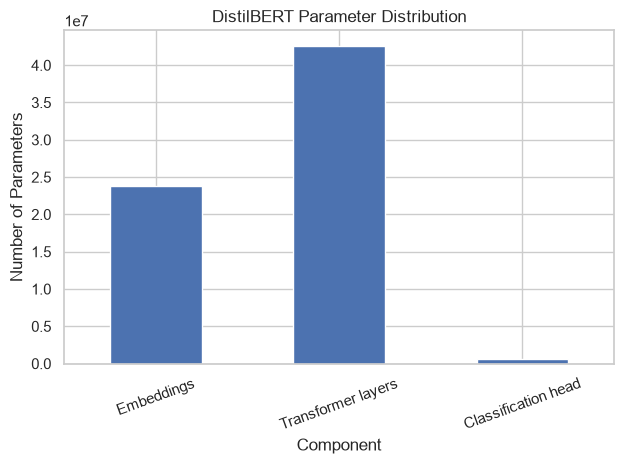

In [25]:
component_df.plot(
    x="Component",
    y="Parameters",
    kind="bar",
    legend=False,
    title="DistilBERT Parameter Distribution"
)

plt.ylabel("Number of Parameters")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 2.1: Self-Attention Idea

Self-attention is a mechanism that allows each token in a sequence to look at other tokens and determine which ones are important for understanding its context.

Each token is transformed into three vectors:

1. **Query (Q):** Represents what information the current token is looking for.
2. **Key (K):** Represents what information each token can offer.
3. **Value (V):** Represents the information that each token contributes to the final output.

The Query of one token is compared with the Keys of all tokens. These similarity scores are converted into attention weights using the softmax function. The weights determine how much each Value vector contributes to the token's new representation.

For example, in the sentence "The animal was tired because it ran", the word "it" may attend strongly to "animal" to help establish the relationship between the words.

Unlike an RNN, which processes tokens sequentially, a Transformer can calculate self-attention for all tokens in a sequence in parallel during training. This makes it easier to learn relationships between distant tokens, although attention can be computationally expensive for long sequences.

# 2.2: Scaled Dot-Product Attention from Scratch

## Create the input sequence

In [26]:
np.random.seed(42)

num_tokens = 4
d_model = 8

X = np.random.randn(num_tokens, d_model)

print("Input X:")
print(X)

print("\nShape of X:", X.shape)

Input X:
[[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696
   1.57921282  0.76743473]
 [-0.46947439  0.54256004 -0.46341769 -0.46572975  0.24196227 -1.91328024
  -1.72491783 -0.56228753]
 [-1.01283112  0.31424733 -0.90802408 -1.4123037   1.46564877 -0.2257763
   0.0675282  -1.42474819]
 [-0.54438272  0.11092259 -1.15099358  0.37569802 -0.60063869 -0.29169375
  -0.60170661  1.85227818]]

Shape of X: (4, 8)


## Create weight matrices

In [27]:
Wq = np.random.randn(d_model, d_model)
Wk = np.random.randn(d_model, d_model)
Wv = np.random.randn(d_model, d_model)

print("Wq shape:", Wq.shape)
print("Wk shape:", Wk.shape)
print("Wv shape:", Wv.shape)

Wq shape: (8, 8)
Wk shape: (8, 8)
Wv shape: (8, 8)


## Calculate Q, K and V

In [28]:
Q = X @ Wq

K = X @ Wk

V = X @ Wv

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: (4, 8)
K shape: (4, 8)
V shape: (4, 8)


## Implement stable softmax

In [29]:
def stable_softmax(scores, axis=-1):

    max_scores = np.max(scores, axis=axis, keepdims=True)

    shifted_scores = scores - max_scores

    exp_scores = np.exp(shifted_scores)

    sum_exp_scores = np.sum(exp_scores, axis=axis, keepdims=True)

    return exp_scores / sum_exp_scores

## Calculate attention scores

In [30]:
d_k = K.shape[1]

raw_scores = Q @ K.T

scores = raw_scores / np.sqrt(d_k)

print("Raw scores shape:", raw_scores.shape)
print("Scaled scores shape:", scores.shape)

print("\nScaled attention scores:")
print(scores)

Raw scores shape: (4, 4)
Scaled scores shape: (4, 4)

Scaled attention scores:
[[-6.22595052  5.51974196 -1.51290328  2.0776227 ]
 [ 3.9156704  -5.01495199 -1.26501828  7.21668366]
 [ 6.2732906  -3.57846232  0.75964575 -6.82973652]
 [-3.53973959  3.0546337  -1.0450873   0.03707887]]


## Calculate attention weights and output

In [31]:
attention_weights = stable_softmax(scores, axis=-1)

output = attention_weights @ V

print("Attention weights shape:", attention_weights.shape)

print("Output shape:", output.shape)

print("\nAttention weights:")
print(attention_weights)

print("\nAttention output:")
print(output)

Attention weights shape: (4, 4)
Output shape: (4, 8)

Attention weights:
[[7.67109958e-06 9.68159817e-01 8.54492061e-04 3.09780198e-02]
 [3.55291769e-02 4.69964577e-06 1.99820777e-04 9.64266303e-01]
 [9.95930547e-01 5.24405365e-05 4.01498126e-03 2.03075101e-06]
 [1.28230159e-03 9.37324806e-01 1.55383143e-02 4.58545778e-02]]

Attention output:
[[-0.68939668 -9.494128   -3.80341092 -5.16705409 -0.79426991  2.65945449
  -0.2745543  -2.76803143]
 [-1.53799964 -3.63883052 -1.78878269 -3.6322275   3.08543646 -3.41871396
   1.81548257 -3.84564413]
 [-0.68259115  8.532587    1.47193389  2.85720415  3.38479494 -2.89007239
  -1.1052181   2.53127537]
 [-0.65523578 -9.31506043 -3.72747038 -5.08239805 -0.78336268  2.60103655
  -0.23924841 -2.78183549]]


## Plot the 4×4 attention heatmap

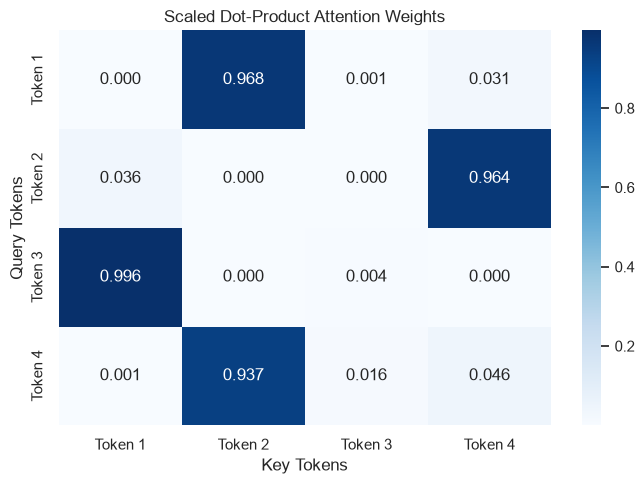

In [32]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    attention_weights,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=["Token 1", "Token 2", "Token 3", "Token 4"],
    yticklabels=["Token 1", "Token 2", "Token 3", "Token 4"]
)

plt.title("Scaled Dot-Product Attention Weights")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
plt.show()

## Verify that each row sums to 1

In [33]:
row_sums = np.sum(attention_weights, axis=1)

print("Attention weight row sums:")
print(row_sums)

print("\nAll rows sum to 1:", np.allclose(row_sums, 1.0))

print("Output shape:", output.shape)
print("All weights are non-negative:", np.all(attention_weights >= 0))

Attention weight row sums:
[1. 1. 1. 1.]

All rows sum to 1: True
Output shape: (4, 8)
All weights are non-negative: True


# 2.3: Why divide by sqrt(d_k)?
## Define the experimen

In [34]:
np.random.seed(42)

num_tokens = 4

dimensions = [4, 256]

results_23 = []

In [35]:
for d_k in dimensions:

    Q_test = np.random.randn(num_tokens, d_k)

    K_test = np.random.randn(num_tokens, d_k)

    raw_scores = Q_test @ K_test.T

    weights_unscaled = stable_softmax(raw_scores, axis=-1)

    scaled_scores = raw_scores / np.sqrt(d_k)

    weights_scaled = stable_softmax(scaled_scores, axis=-1)

    max_prob_unscaled = np.mean(np.max(weights_unscaled, axis=1))
    max_prob_scaled = np.mean(np.max(weights_scaled, axis=1))

    epsilon = 1e-12

    entropy_unscaled = np.mean(
        -np.sum(
            weights_unscaled * np.log(weights_unscaled + epsilon),
            axis=1
        )
    )

    entropy_scaled = np.mean(
        -np.sum(
            weights_scaled * np.log(weights_scaled + epsilon),
            axis=1
        )
    )

    results_23.append({
        "d_k": d_k,
        "Scaling": "Without scaling",
        "Mean max probability": max_prob_unscaled,
        "Mean entropy": entropy_unscaled
    })

    results_23.append({
        "d_k": d_k,
        "Scaling": "With scaling",
        "Mean max probability": max_prob_scaled,
        "Mean entropy": entropy_scaled
    })

## Display the comparison table

In [36]:
df_attention = pd.DataFrame(results_23)

df_attention["Mean max probability"] = (
    df_attention["Mean max probability"].round(4)
)

df_attention["Mean entropy"] = df_attention["Mean entropy"].round(4)

display(df_attention)

,d_k,Scaling,Mean max probability,Mean entropy
0,4,Without scaling,0.6500,0.8810
1,4,With scaling,0.4741,1.2075
2,256,Without scaling,0.9995,0.0040
3,256,With scaling,0.5381,1.1099


## Plot maximum probability comparison

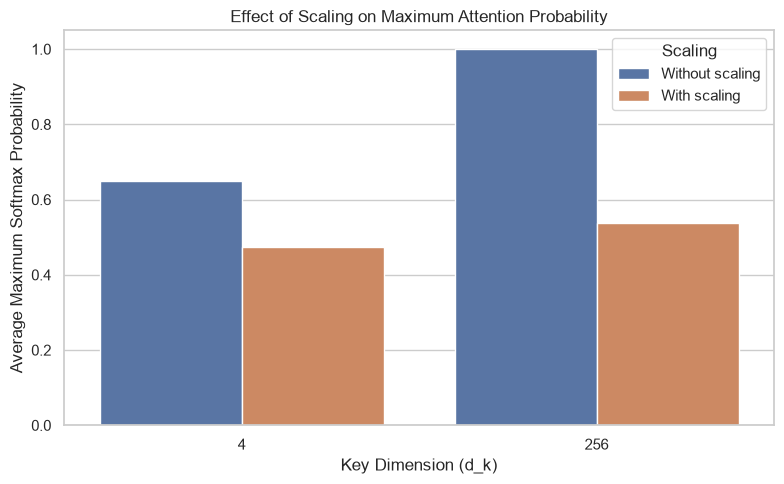

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_attention,
    x="d_k",
    y="Mean max probability",
    hue="Scaling"
)

plt.title("Effect of Scaling on Maximum Attention Probability")
plt.xlabel("Key Dimension (d_k)")
plt.ylabel("Average Maximum Softmax Probability")
plt.legend(title="Scaling")
plt.tight_layout()
plt.show()

## Plot entropy comparison

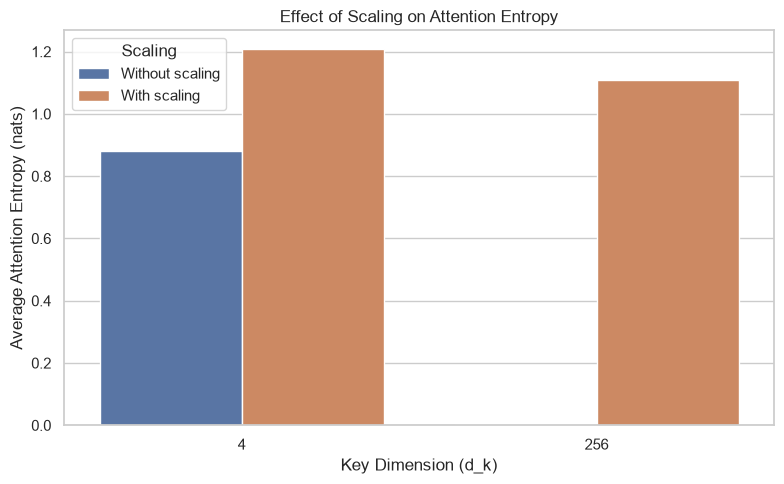

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_attention,
    x="d_k",
    y="Mean entropy",
    hue="Scaling"
)

plt.title("Effect of Scaling on Attention Entropy")
plt.xlabel("Key Dimension (d_k)")
plt.ylabel("Average Attention Entropy (nats)")
plt.legend(title="Scaling")
plt.tight_layout()
plt.show()

# Why Do We Divide by the Square Root of the Key Dimension?

Scaled dot-product attention is calculated as:

\[
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

Here, \(d_k\) is the dimension of each Query and Key vector.

When Query and Key components have approximately zero mean, unit variance, and are independent, the variance of their dot product grows approximately in proportion to \(d_k\). As the dimension increases, the unscaled scores can become large in magnitude.

Large score differences can push softmax into a saturated region, where one probability approaches 1 and the remaining probabilities approach 0. In a trainable attention layer, this can produce very small gradients for many inputs and make optimization harder.

Dividing the scores by \(\sqrt{d_k}\) helps keep their variance near 1 under these assumptions. This usually produces more balanced attention probabilities and helps maintain useful gradients during training.

In this experiment, the mean maximum probability measures how concentrated the attention is. The average entropy measures how spread out the attention distribution is. For four tokens, entropy ranges from approximately 0 for a highly concentrated distribution to \(\ln(4)\), or approximately 1.386 nats, for a uniform distribution.

The unscaled \(d_k=256\) case will often have more concentrated attention than the scaled case. The exact values depend on the random samples, so conclusions should be based on the actual results printed by the notebook.

# 2.4: Self-Attention vs Luong Attention

## Create encoder and decoder states

In [39]:
np.random.seed(42)

encoder_states = np.random.randn(5, 8)
decoder_state = np.random.randn(8)

print("Encoder states shape:", encoder_states.shape)

print("Decoder state shape:", decoder_state.shape)

Encoder states shape: (5, 8)
Decoder state shape: (8,)


## Implement Luong dot-product attention

In [40]:
def stable_softmax(scores, axis=-1):

    shifted_scores = scores - np.max(scores, axis=axis, keepdims=True)

    exp_scores = np.exp(shifted_scores)

    denominator = np.sum(exp_scores, axis=axis, keepdims=True)

    return exp_scores / denominator


scores = encoder_states @ decoder_state

weights = stable_softmax(scores)

context = weights @ encoder_states

print("Attention scores:")
print(scores)

print("\nAttention weights:")
print(weights)

print("\nContext vector:")
print(context)

print("\nContext shape:", context.shape)

print("Weights sum to 1:", np.isclose(weights.sum(), 1.0))

Attention scores:
[ 0.40818741  1.1597874  -3.70553788  2.97027193  2.00301742]

Attention weights:
[0.04755781 0.10084111 0.00077742 0.61648294 0.23434072]

Context vector:
[-0.36327268 -0.13110175 -0.53344695 -0.03011265 -0.30693492 -0.8433026
 -0.78097616  1.1667187 ]

Context shape: (8,)
Weights sum to 1: True


## Visualize Luong attention weights

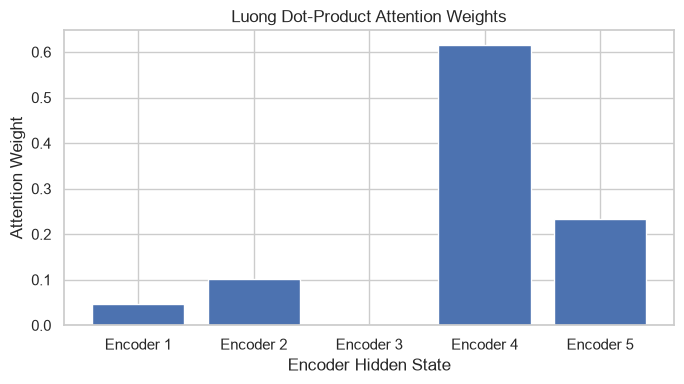

In [41]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Encoder 1", "Encoder 2", "Encoder 3", "Encoder 4", "Encoder 5"],
    weights)

plt.title("Luong Dot-Product Attention Weights")
plt.xlabel("Encoder Hidden State")
plt.ylabel("Attention Weight")
plt.tight_layout()
plt.show()

# Luong Attention vs Self-Attention

| Feature | Luong Dot-Product Attention | Self-Attention |
|---|---|---|
| Query (Q) | Decoder hidden state | Each token's representation, transformed by a learned projection |
| Key (K) | Encoder hidden states | Representations of tokens in the same sequence |
| Value (V) | Usually encoder hidden states | Projected representations of tokens in the same sequence |
| What is attended over? | A decoder state attends over encoder states | Every token can attend over tokens in the same sequence |
| Does it require an RNN? | In its original sequence-to-sequence setting, it commonly uses an RNN encoder and decoder, but the attention calculation itself does not require an RNN | No. Transformer self-attention does not require an RNN |
| Parallelism | In a traditional autoregressive RNN decoder, decoding steps are sequential | All token positions can be processed in parallel during training |
| Architecture location | Between encoder outputs and decoder state in an encoder-decoder sequence-to-sequence model | Inside Transformer encoder or decoder blocks |

## Observation

Luong attention selects relevant encoder states for a decoder state. Self-attention instead lets tokens build contextual representations by attending to other tokens in the same sequence. Both mechanisms calculate attention weights and use them to combine value vectors.

# 2.5: Attention Is Order-Blind

## Define a reusable self-attention function

In [42]:
def self_attention(X, Wq, Wk, Wv):

    Q = X @ Wq

    K = X @ Wk

    V = X @ Wv

    scores = (Q @ K.T) / np.sqrt(K.shape[1])

    weights = stable_softmax(scores, axis=-1)

    output = weights @ V

    return output, weights


original_output, original_weights = self_attention(X, Wq, Wk, Wv)

print("Original output shape:", original_output.shape)

Original output shape: (4, 8)


## Shuffle the input rows

In [43]:
permutation = np.array([2, 0, 3, 1])

X_shuffled = X[permutation]

print("Permutation:", permutation)

print("Shuffled input shape:", X_shuffled.shape)

shuffled_output, shuffled_weights = self_attention(
    X_shuffled, Wq, Wk, Wv
)

print("\nShuffled output:")
print(shuffled_output)

Permutation: [2 0 3 1]
Shuffled input shape: (4, 8)

Shuffled output:
[[-0.68259115  8.532587    1.47193389  2.85720415  3.38479494 -2.89007239
  -1.1052181   2.53127537]
 [-0.68939668 -9.494128   -3.80341092 -5.16705409 -0.79426991  2.65945449
  -0.2745543  -2.76803143]
 [-0.65523578 -9.31506043 -3.72747038 -5.08239805 -0.78336268  2.60103655
  -0.23924841 -2.78183549]
 [-1.53799964 -3.63883052 -1.78878269 -3.6322275   3.08543646 -3.41871396
   1.81548257 -3.84564413]]


## Verify the permutation property

In [44]:
restored_output = np.empty_like(shuffled_output)

restored_output[permutation] = shuffled_output

outputs_match = np.allclose(
    original_output,
    restored_output,
    atol=1e-8
)

print("Original and restored outputs match:", outputs_match)

max_difference = np.max(np.abs(original_output - restored_output))

print("Maximum absolute difference:", max_difference)

Original and restored outputs match: True
Maximum absolute difference: 1.7763568394002505e-15


# 2.6: Verify Attention Against a Real DistilBERT Model
## Load DistilBERT with eager attention

In [45]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    attn_implementation="eager"
)

model.eval()

num_heads = model.config.n_heads

hidden_size = model.config.dim

head_dim = hidden_size // num_heads

print("Number of attention heads:", num_heads)
print("Hidden size:", hidden_size)
print("Dimension per head:", head_dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Number of attention heads: 12
Hidden size: 768
Dimension per head: 64


## Inspect the model architecture

In [46]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

## Tokenize one sentence

In [47]:
text = "Transformers can learn relationships between words."

inputs = tok(
    text,
    return_tensors="pt"
)

print("Input IDs:")
print(inputs["input_ids"])

print("\nAttention mask:")
print(inputs["attention_mask"])

print("\nTokens:")
print(tok.convert_ids_to_tokens(inputs["input_ids"][0]))

Input IDs:
tensor([[  101, 19081,  2064,  4553,  6550,  2090,  2616,  1012,   102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1]])

Tokens:
['[CLS]', 'transformers', 'can', 'learn', 'relationships', 'between', 'words', '.', '[SEP]']


## Get hidden states and attention weights

In [48]:
with torch.no_grad():

    outputs = model.distilbert(
        **inputs,
        output_hidden_states=True,
        output_attentions=True,
        return_dict=True
    )

hidden_states = outputs.hidden_states[0]

actual_attention = outputs.attentions[0]

print("Initial hidden states shape:", hidden_states.shape)
print("Actual attention shape:", actual_attention.shape)

Initial hidden states shape: torch.Size([1, 9, 768])
Actual attention shape: torch.Size([1, 12, 9, 9])


## Recompute Query and Key projections manually

In [49]:
first_layer = model.distilbert.transformer.layer[0]

Q = first_layer.attention.q_lin(hidden_states)

K = first_layer.attention.k_lin(hidden_states)

print("Q shape:", Q.shape)
print("K shape:", K.shape)

Q shape: torch.Size([1, 9, 768])
K shape: torch.Size([1, 9, 768])


## Split into attention heads

In [50]:
batch_size = hidden_states.shape[0]
seq_length = hidden_states.shape[1]

Q_heads = Q.view(
    batch_size, seq_length, num_heads, head_dim).permute(0, 2, 1, 3)

K_heads = K.view(
    batch_size, seq_length, num_heads, head_dim).permute(0, 2, 1, 3)

print("Q heads shape:", Q_heads.shape)
print("K heads shape:", K_heads.shape)

Q heads shape: torch.Size([1, 12, 9, 64])
K heads shape: torch.Size([1, 12, 9, 64])


## Calculate attention scores and apply mask

In [51]:
scores = torch.matmul(
    Q_heads,
    K_heads.transpose(-1, -2)
)

scores = scores / np.sqrt(head_dim)

mask = inputs["attention_mask"][:, None, None, :]

scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)

manual_attention = torch.softmax(scores, dim=-1)

print("Manual attention shape:", manual_attention.shape)

Manual attention shape: torch.Size([1, 12, 9, 9])


## Compare manual and actual attention

In [52]:
manual_head = manual_attention[0, 0]

actual_head = actual_attention[0, 0]

manual_array = manual_head.detach().cpu().numpy()

actual_array = actual_head.detach().cpu().numpy()

max_difference = np.max(np.abs(manual_array - actual_array))

matches = np.allclose(
    manual_array,
    actual_array,
    atol=1e-4,
    rtol=1e-4
)

print("Manual attention matches actual attention:", matches)
print("Maximum absolute difference:", max_difference)


Manual attention matches actual attention: True
Maximum absolute difference: 0.0


## Plot both attention matrices

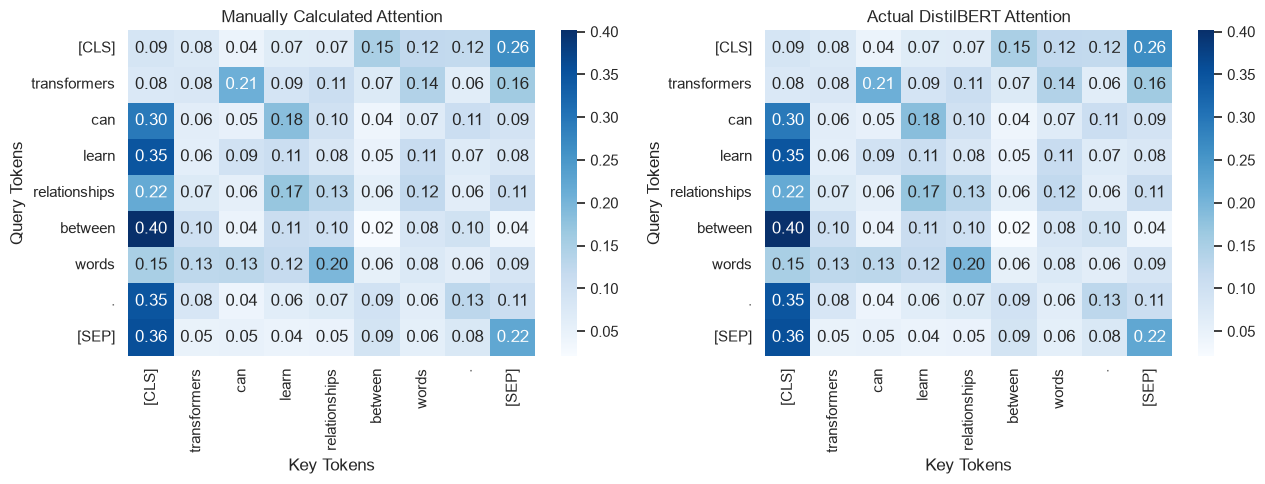

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])

sns.heatmap(
    manual_array,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=tokens,
    yticklabels=tokens,
    ax=axes[0])

sns.heatmap(
    actual_array,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=tokens,
    yticklabels=tokens,
    ax=axes[1])

axes[0].set_title("Manually Calculated Attention")
axes[1].set_title("Actual DistilBERT Attention")

for ax in axes:
    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")

plt.tight_layout()
plt.show()


# 3.1 Multi-Head Attention

Multi-head attention helps a Transformer learn different relationships between words at the same time.

A single attention head may focus on one type of relationship, such as nearby words, while another head may focus on relationships between words that are far apart.

In DistilBERT:
- The hidden dimension (`d_model`) is 768.
- There are 12 attention heads.
- Each head uses a smaller dimension of 64 because 768 = 12 × 64.
- Every head has its own Query (Q), Key (K), and Value (V) projections.
- Each head calculates its own attention pattern.
- The outputs of all 12 heads are concatenated.
- An output projection combines the concatenated results.

Multi-head attention allows the model to learn different word relationships in parallel. Although it uses multiple heads, the main projection and attention computation is approximately similar in scale to one large attention operation with the same total hidden dimension.

**Conclusion:** Multiple attention heads help DistilBERT capture different types of relationships between words.


# 3.2: Extract and Plot Real Attention Heads
## prepare the sentence

In [54]:
from transformers import AutoTokenizer, AutoModel

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load DistilBERT without the classification layer
model = AutoModel.from_pretrained(
    model_name,
    attn_implementation="eager")

model.eval()

# Store the required sentence
sentence = "The animal did not cross the street because it was too tired."

# Convert the sentence into model input tensors
inputs = tokenizer(sentence, return_tensors="pt")

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)
print("Number of tokens:", len(tokens))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Tokens: ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']
Number of tokens: 15


## Extract actual attention weights

In [55]:
# Disable gradient tracking because we only need inference results
with torch.no_grad():

    outputs = model(
        **inputs,
        output_attentions=True,
        return_dict=True
    )

attentions = outputs.attentions

print("Number of attention layers:", len(attentions))

# Print the shape of each layer's attention tensor
for layer_number, attention in enumerate(attentions, start=1):

    # Display the current layer number and tensor shape
    print(f"Layer {layer_number} shape: {tuple(attention.shape)}")

Number of attention layers: 6
Layer 1 shape: (1, 12, 15, 15)
Layer 2 shape: (1, 12, 15, 15)
Layer 3 shape: (1, 12, 15, 15)
Layer 4 shape: (1, 12, 15, 15)
Layer 5 shape: (1, 12, 15, 15)
Layer 6 shape: (1, 12, 15, 15)


## Plot six attention heads in a 2×3 grid

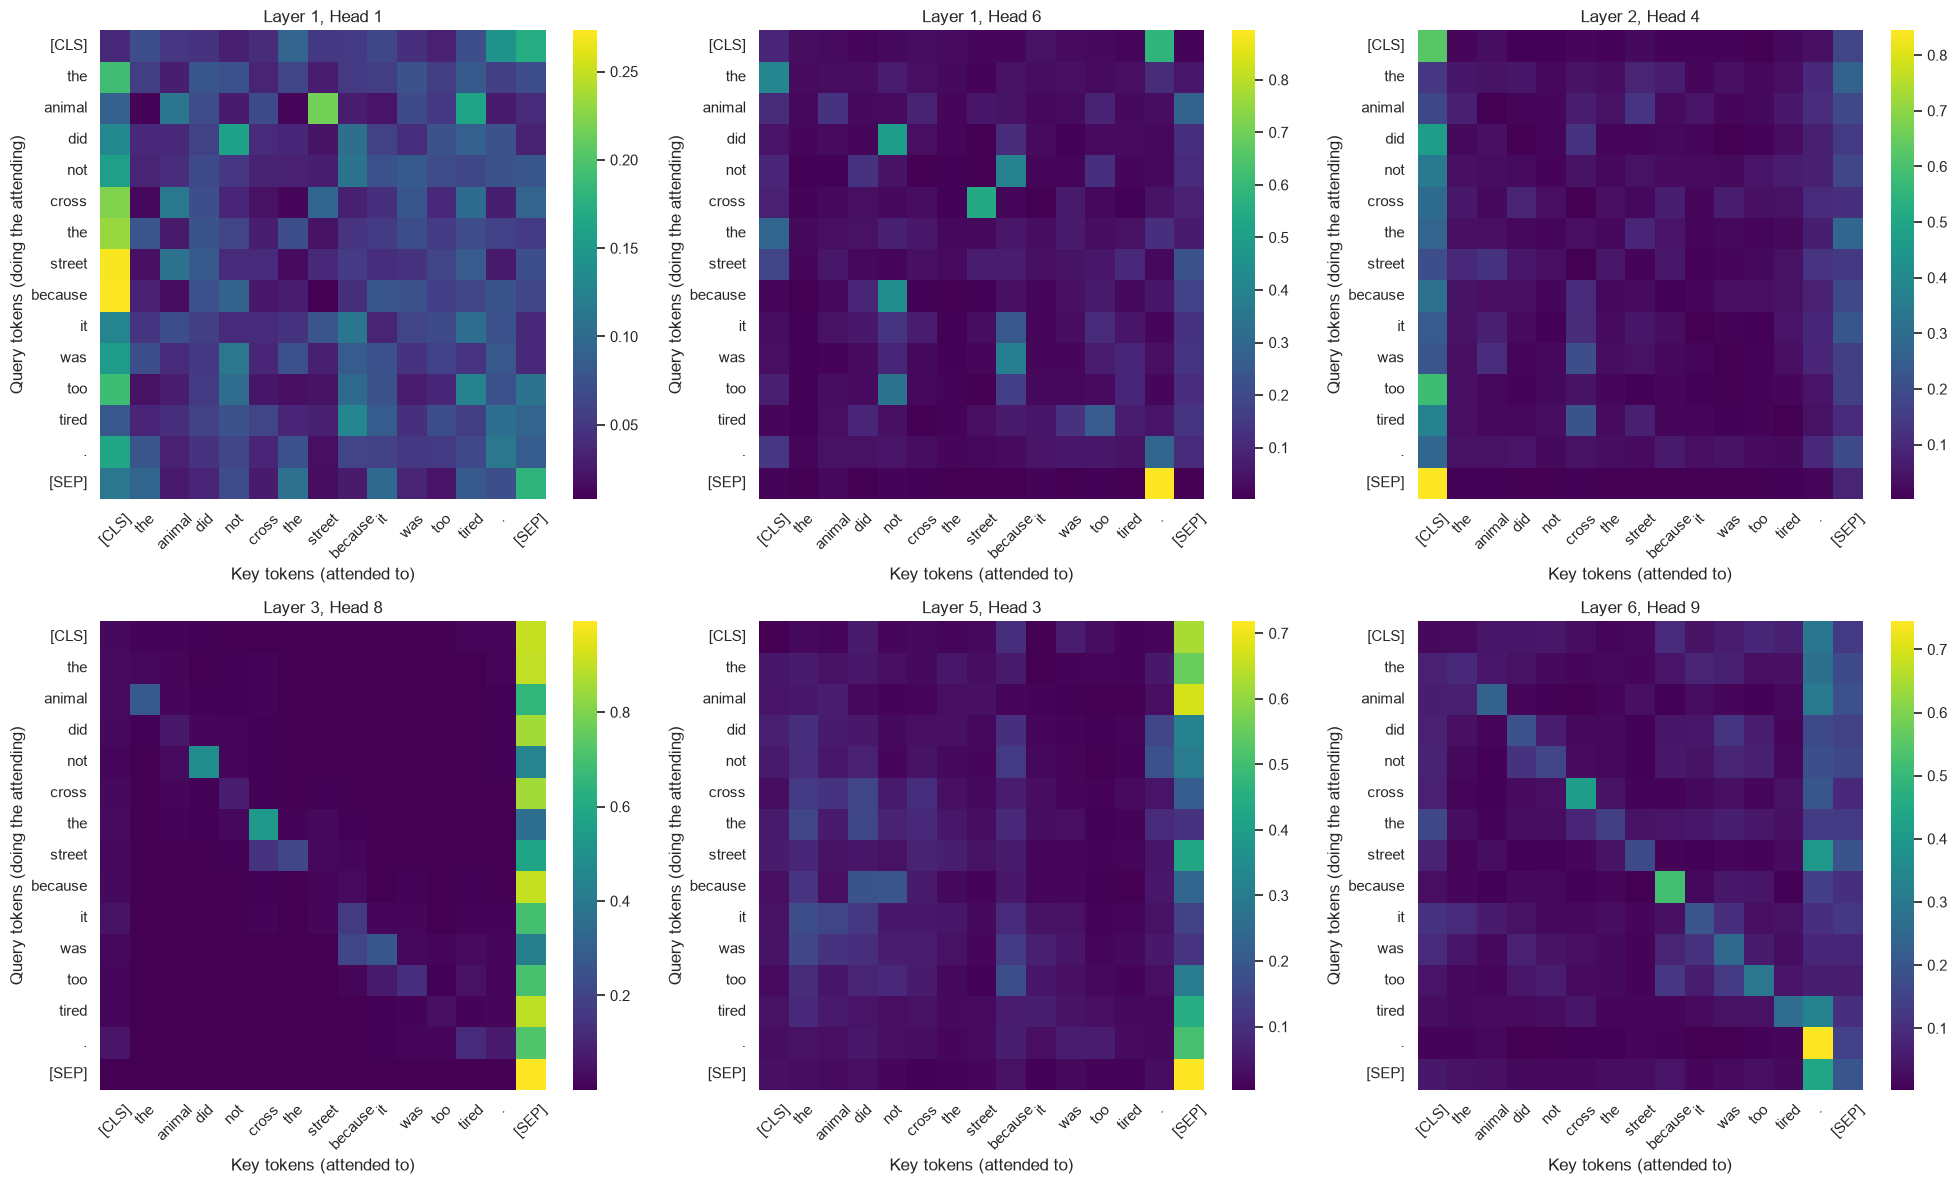

In [56]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

selected_heads = [
    (0, 0),  # Layer 1, Head 1
    (0, 5),  # Layer 1, Head 6
    (1, 3),  # Layer 2, Head 4
    (2, 7),  # Layer 3, Head 8
    (4, 2),  # Layer 5, Head 3
    (5, 8)   # Layer 6, Head 9
]

for ax, (layer_index, head_index) in zip(axes.flat, selected_heads):

    attention_matrix = attentions[layer_index][0, head_index]

    # Convert the tensor to a NumPy array
    attention_matrix = attention_matrix.cpu().numpy()

    sns.heatmap(
        attention_matrix,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        ax=ax)

    ax.set_title(
        f"Layer {layer_index + 1}, Head {head_index + 1}")

    ax.set_xlabel("Key tokens (attended to)")
    ax.set_ylabel("Query tokens (doing the attending)")

    ax.tick_params(axis="x", labelrotation=45)
    ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()


## Observations from Real Attention Heads

1. **Attention to nearby tokens:** Some heads may assign stronger attention to nearby words, such as a word and the word immediately before it. This can help the model capture local context.

2. **Attention to special tokens:** Some heads may give noticeable attention to `[CLS]` or `[SEP]`. These special tokens mark the beginning and end of the input sequence.

3. **Relationships between words:** In some heads, the pronoun `it` may attend strongly to another word in the sentence, potentially helping the model represent relationships between words.

**Important:** These behaviours are examples to look for, not guaranteed results for every head. The heatmaps show attention weights, but attention alone does not prove exactly how the model understands a sentence.


# 3.3: Head Diversity Measurement

## Calculate average entropy for each head

In [57]:
layers_to_check = {
    "First Layer (Layer 0)": attentions[0],
    "Last Layer (Layer 5)": attentions[-1]
}

entropy_results = {}

for layer_name, attention in layers_to_check.items():

    safe_attention = attention.clamp(min=1e-12)

    token_entropy = -(attention * torch.log(safe_attention)).sum(dim=-1)

    head_entropy = token_entropy.mean(dim=(0, 2))

    entropy_results[layer_name] = head_entropy.detach().cpu().numpy()

    print("\n", layer_name)

    for head_index, entropy_value in enumerate(entropy_results[layer_name]):
        print(f"Head {head_index + 1}: {entropy_value:.4f}")


 First Layer (Layer 0)
Head 1: 2.5257
Head 2: 2.0577
Head 3: 0.5284
Head 4: 1.2367
Head 5: 2.3098
Head 6: 2.0078
Head 7: 2.2635
Head 8: 1.7786
Head 9: 1.8250
Head 10: 1.6204
Head 11: 0.6730
Head 12: 1.8904

 Last Layer (Layer 5)
Head 1: 1.3842
Head 2: 1.6553
Head 3: 1.8735
Head 4: 1.6839
Head 5: 1.3674
Head 6: 1.7384
Head 7: 1.7882
Head 8: 0.9344
Head 9: 2.1014
Head 10: 2.0427
Head 11: 1.6762
Head 12: 1.4065


## Plot the two bar charts

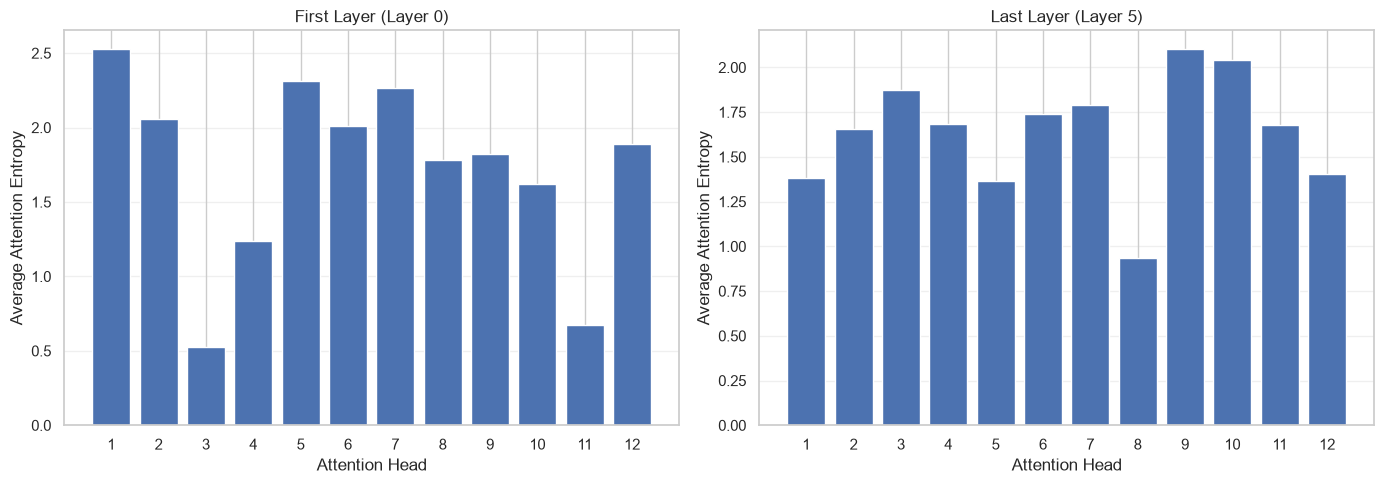

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (layer_name, entropy_values) in zip(
    axes, entropy_results.items()):

    head_numbers = np.arange(1, len(entropy_values) + 1)

    ax.bar(head_numbers, entropy_values)

    # Add the chart title and axis labels
    ax.set_title(layer_name)
    ax.set_xlabel("Attention Head")
    ax.set_ylabel("Average Attention Entropy")

    ax.set_xticks(head_numbers)

    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 3.4: Sinusoidal Positional Encoding from Scratch
## Create positional encoding

In [59]:
num_positions = 50
d_model = 128

positions = np.arange(num_positions).reshape(-1, 1)

dimensions = np.arange(d_model).reshape(1, -1)

angle_rates = 1 / np.power(
    10000,
    (2 * (dimensions // 2)) / d_model
)

angles = positions * angle_rates

positional_encoding = np.zeros((num_positions, d_model))

positional_encoding[:, 0::2] = np.sin(angles[:, 0::2])

positional_encoding[:, 1::2] = np.cos(angles[:, 1::2])

print("Positional encoding shape:", positional_encoding.shape)

print(positional_encoding[:5, :8])

Positional encoding shape: (50, 128)
[[ 0.          1.          0.          1.          0.          1.
   0.          1.        ]
 [ 0.84147098  0.54030231  0.76172041  0.64790587  0.68156135  0.73176098
   0.60469402  0.79645787]
 [ 0.90929743 -0.41614684  0.98704625 -0.16043596  0.99748     0.07094825
   0.96322662  0.26869029]
 [ 0.14112001 -0.9899925   0.51730572 -0.85580068  0.77827252 -0.62792665
   0.92964484 -0.36845688]
 [-0.7568025  -0.65364362 -0.31671543 -0.9485206   0.14153892 -0.98993269
   0.51761928 -0.85561105]]


## Plot the positional encoding heatmap

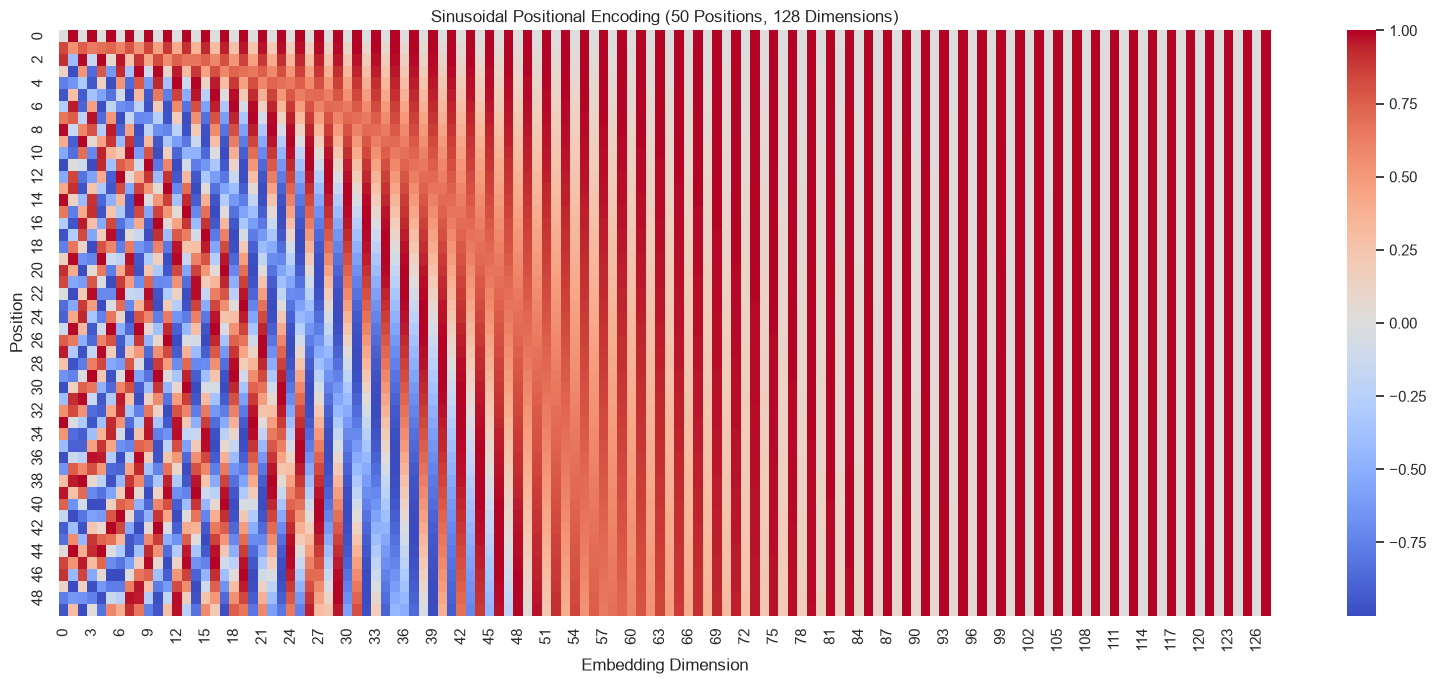

In [60]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    positional_encoding,
    cmap="coolwarm",
    center=0)

plt.title("Sinusoidal Positional Encoding (50 Positions, 128 Dimensions)")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.tight_layout()
plt.show()


## Why Use Sines and Cosines?

Sinusoidal positional encoding uses sine and cosine functions at different frequencies to give each position a distinctive pattern. These patterns help the Transformer distinguish token positions and learn relationships between relative offsets. The encoding can be added directly to token embeddings because both have the same dimension.


# 3.5: Position Makes Identical Words Different

## Compare cosine similarity

In [61]:
np.random.seed(42)
word_embedding = np.random.randn(128)

# Select positional encodings for positions 3 and 20
position_3 = positional_encoding[3]
position_20 = positional_encoding[20]

# Calculate cosine similarity without positional encoding
similarity_without_pe = np.dot(
    word_embedding, word_embedding
) / (
    np.linalg.norm(word_embedding) *
    np.linalg.norm(word_embedding)
)

word_at_position_3 = word_embedding + position_3

word_at_position_20 = word_embedding + position_20

dot_product = np.dot(
    word_at_position_3,
    word_at_position_20)

norm_product = (
    np.linalg.norm(word_at_position_3) *
    np.linalg.norm(word_at_position_20))

similarity_with_pe = dot_product / norm_product

print("Similarity without positional encoding:",
      round(similarity_without_pe, 4))

print("Similarity with positional encoding:",
      round(similarity_with_pe, 4))

Similarity without positional encoding: 1.0
Similarity with positional encoding: 0.8595



## Conclusion: Positional Encoding and Word Order

Without positional encoding, the same word embedding remains identical at different positions, so its cosine similarity with itself is 1.0. Adding positional encodings changes the vectors according to their positions, making the representations different. This connects to Task 2.5: self-attention without positional information is permutation-equivariant, while adding positional encoding supplies information about token order. Positional encoding helps the model distinguish positions, although it does not guarantee that every pair of position-adjusted vectors has a unique cosine similarity.

# 3.6: Learned Positional Embeddings in a Real Model
## Inspect position embeddings

In [62]:
position_layer = model.embeddings.position_embeddings

position_weights = position_layer.weight

print("Position embedding shape:", tuple(position_weights.shape))

first_64_positions = position_weights[:64]

position_array = first_64_positions.detach().cpu().numpy()

position_norms = np.linalg.norm(position_array, axis=1, keepdims=True)

# Calculate the cosine similarity matrix
cosine_similarity = (
    position_array @ position_array.T
) / (
    position_norms @ position_norms.T
)

print("Cosine similarity shape:", cosine_similarity.shape)

Position embedding shape: (512, 768)
Cosine similarity shape: (64, 64)


## Plot the cosine-similarity heatmap

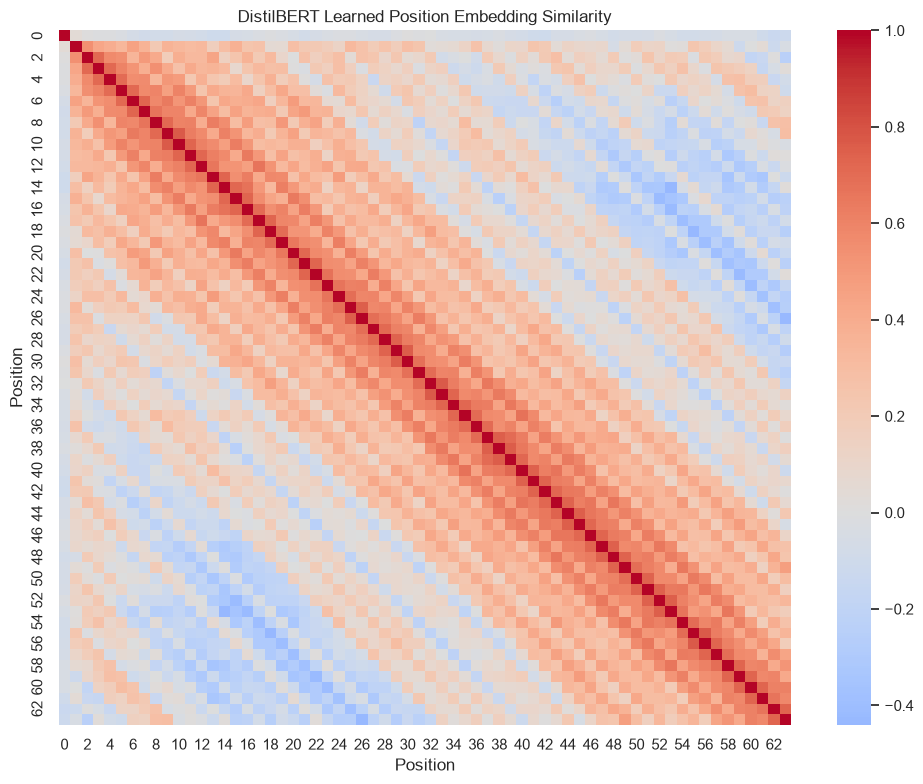

In [63]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cosine_similarity,
    cmap="coolwarm",
    center=0)

plt.title("DistilBERT Learned Position Embedding Similarity")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.show()


## Learned Positional Embeddings

BERT-style models such as DistilBERT learn position vectors during training instead of calculating them from fixed sine and cosine functions. DistilBERT's position embedding table contains 512 vectors, each with 768 dimensions, so the model's position embedding table supports positions up to 512.

T5 uses relative position biases instead, representing positional relationships differently; this will be explored in Task 5.


# 3.7: Layer Normalization from Scratch

## Create a random matrix and implement LayerNorm

In [64]:
np.random.seed(42)
X = np.random.randn(4, 8)

gamma = np.ones(8)       # Scale parameter
beta = np.zeros(8)       # Shift parameter
epsilon = 1e-5           # Small value to prevent division by zero

token_mean = np.mean(X, axis=1, keepdims=True)

token_variance = np.var(X, axis=1, keepdims=True)

# Normalize each token vector
X_normalized = (X - token_mean) / np.sqrt(token_variance + epsilon)

Y_numpy = gamma * X_normalized + beta

print("NumPy LayerNorm output:\n", Y_numpy)

print("\nMean of each token:")
print(np.mean(Y_numpy, axis=1))

print("\nStandard deviation of each token:")
print(np.std(Y_numpy, axis=1))

NumPy LayerNorm output:
 [[-0.07900015 -1.00407124  0.14094753  1.41619229 -1.14376765 -1.14374373
   1.49804267  0.31540028]
 [ 0.16641908  1.4389799   0.17403494  0.17112769  1.06099973 -1.64906339
  -1.41221115  0.0497132 ]
 [-0.66614918  0.7578747  -0.55368579 -1.09480394  1.99338804  0.17840138
   0.4931323  -1.10815751]
 [-0.50911118  0.25246726 -1.2140982   0.56018223 -0.57449037 -0.21544276
  -0.57573148  2.2762245 ]]

Mean of each token:
[-8.32667268e-17  2.77555756e-17 -5.55111512e-17  2.77555756e-17]

Standard deviation of each token:
[0.99998939 0.99999209 0.99999424 0.99999325]


## Compare with PyTorch LayerNorm

In [65]:
X_torch = torch.tensor(X, dtype=torch.float32)

layer_norm = torch.nn.LayerNorm(
    normalized_shape=8,
    eps=epsilon,
    elementwise_affine=True)

# Set gamma to 1 and beta to 0
with torch.no_grad():
    layer_norm.weight.fill_(1.0)
    layer_norm.bias.fill_(0.0)

Y_torch = layer_norm(X_torch)

Y_torch_array = Y_torch.detach().numpy()

print(
    "NumPy and PyTorch outputs match:",
    torch.allclose(
        torch.tensor(Y_numpy, dtype=torch.float32),
        Y_torch,
        atol=1e-5,
        rtol=1e-5
    )
)

print(
    "Maximum absolute difference:",
    np.max(np.abs(Y_numpy - Y_torch_array))
)

NumPy and PyTorch outputs match: True
Maximum absolute difference: 1.5385099527698287e-07


# 3.8: LayerNorm vs BatchNorm
## Apply BatchNorm to the same matrix

In [66]:
X_torch = torch.tensor(X, dtype=torch.float32)

batch_norm = torch.nn.BatchNorm1d(
    num_features=8,
    eps=1e-5,
    affine=False,
    track_running_stats=False)

# Use current batch statistics
batch_norm.train()

Y_batch = batch_norm(X_torch)

# Convert the result to NumPy
Y_batch_array = Y_batch.detach().numpy()

print("BatchNorm output:\n", Y_batch_array)

BatchNorm output:
 [[ 1.6024408  -1.375443    1.6177137   1.4044282  -0.58015454  0.5997484
   1.4626967   0.48679212]
 [-0.15853107  1.3339083   0.00763518 -0.43571317  0.0304693  -1.7309594
  -1.3002727  -0.5756321 ]
 [-1.1488512   0.42533433 -0.63663375 -1.3115505   1.5998614   0.6113533
   0.19860072 -1.2647227 ]
 [-0.2950588  -0.38379973 -0.9887153   0.34283546 -1.0501761   0.51985765
  -0.36102462  1.3535626 ]]


## Calculate token's mean & standard deviation

In [67]:
batch_token_means = np.mean(Y_batch_array, axis=1)

batch_token_stds = np.std(Y_batch_array, axis=1)

print("\nPer-token means after BatchNorm:")
print(batch_token_means)

print("\nPer-token standard deviations after BatchNorm:")
print(batch_token_stds)

print("\nPer-feature means across tokens:")
print(np.mean(Y_batch_array, axis=0))

print("\nPer-feature standard deviations across tokens:")
print(np.std(Y_batch_array, axis=0))


Per-token means after BatchNorm:
[ 0.6522778  -0.35363698 -0.19082604 -0.10781486]

Per-token standard deviations after BatchNorm:
[1.0439153  0.8669692  0.9941827  0.75598085]

Per-feature means across tokens:
[-4.4703484e-08 -1.4901161e-08 -5.9604645e-08  7.4505806e-09
  0.0000000e+00 -2.9802322e-08  1.4901161e-08 -2.9802322e-08]

Per-feature standard deviations across tokens:
[0.99998343 0.9999208  0.9999895  0.99999565 0.9999918  0.9999904
 0.9999964  0.9999968 ]



## LayerNorm vs BatchNorm

| Feature | Layer Normalization | Batch Normalization |
|---|---|---|
| What is normalized? | Features within each token | Each feature across the batch |
| Batch size dependence | Does not depend on other batch examples | Training statistics depend on the batch |
| Variable-length sequences and padding | Works independently per token, though padded positions still need proper masking | Padding and batch composition can affect feature statistics |
| Common use | Transformers and sequence models | Common in CNNs and many feed-forward networks |

Transformers commonly use LayerNorm because each token can be normalized independently without relying on statistics collected across other tokens or examples. This is useful for variable-length sequences and different batch sizes.

In the BatchNorm experiment, the matrix has four tokens and eight features. BatchNorm calculates statistics for each of the eight features across the four tokens, whereas LayerNorm calculates statistics separately across the eight features of each token.


## Inspect DistilBERT's embedding LayerNorm

In [68]:
embedding_layer_norm = model.embeddings.LayerNorm

gamma_distilbert = embedding_layer_norm.weight
beta_distilbert = embedding_layer_norm.bias

print("Gamma shape:", tuple(gamma_distilbert.shape))
print("Beta shape:", tuple(beta_distilbert.shape))

print("\nFirst 10 gamma values:")
print(gamma_distilbert[:10].detach().cpu().numpy())

print("\nFirst 10 beta values:")
print(beta_distilbert[:10].detach().cpu().numpy())

print("\nLayerNorm epsilon:", embedding_layer_norm.eps)

Gamma shape: (768,)
Beta shape: (768,)

First 10 gamma values:
[0.84250426 0.80054885 0.7313251  0.7595404  0.79776627 0.7835383
 0.8177085  0.8188755  0.8397658  0.7093651 ]

First 10 beta values:
[ 0.04429721  0.05969742  0.06616086  0.08707297 -0.05961614 -0.1600142
  0.14140809 -0.05989302 -0.02717386  0.12062009]

LayerNorm epsilon: 1e-12



## Conclusion

DistilBERT's embedding LayerNorm learns 768 scale parameters (gamma) and 768 shift parameters (beta). Gamma scales the normalized features, while beta shifts them. Unlike the initial NumPy experiment, where gamma was fixed to 1 and beta to 0, these parameters are learned during model training.



# 4.1 Transformer Encoder Architecture

A Transformer encoder starts with token embeddings and positional information. These are combined and passed through six stacked Transformer blocks in DistilBERT.

Each encoder block contains:

1. **Multi-Head Self-Attention:** Each token can attend to other tokens in the input sequence.
2. **Residual Connection and Layer Normalization:** The input to the attention sublayer is added to its output, followed by normalization.
3. **Position-wise Feed-Forward Network:** A linear layer expands the hidden dimension from 768 to 3072, applies a non-linear activation, and another linear layer projects it back from 3072 to 768.
4. **Residual Connection and Layer Normalization:** The feed-forward input is added to its output, followed by normalization.

### Encoder flow

Token embeddings + positional embeddings
→ Embedding LayerNorm
→ Encoder Block 1
→ Encoder Block 2
→ Encoder Block 3
→ Encoder Block 4
→ Encoder Block 5
→ Encoder Block 6
→ Contextual token representations

Each of DistilBERT's six blocks contains multi-head self-attention, a feed-forward network, and two LayerNorm modules.

**Bidirectional context:** In an encoder, each token can attend to tokens on both its left and right, subject to the attention mask. This helps the model build contextual representations using the full input sequence.


# 4.2: Print and Read the Real Encoder
## Load and print the model architecture

In [69]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased-finetuned-sst-2-english",
    attn_implementation="eager"
)

print(model.distilbert)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

## classification head separately

In [70]:
print("Classification Head:")
print(model.pre_classifier)
print(model.classifier)

Classification Head:
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=2, bias=True)


## Print important module names

In [71]:
encoder = model.distilbert

print("Token embedding:")
print(encoder.embeddings.word_embeddings)

print("\nPosition embedding:")
print(encoder.embeddings.position_embeddings)

print("\nEmbedding LayerNorm:")
print(encoder.embeddings.LayerNorm)

# Select the first Transformer block
block = encoder.transformer.layer[0]

print("\nQuery projection:")
print(block.attention.q_lin)

print("\nKey projection:")
print(block.attention.k_lin)

print("\nValue projection:")
print(block.attention.v_lin)

print("\nOutput projection:")
print(block.attention.out_lin)

print("\nFeed-forward linear layer 1:")
print(block.ffn.lin1)

print("\nFeed-forward activation:")
print(block.ffn.activation)

print("\nFeed-forward linear layer 2:")
print(block.ffn.lin2)

print("\nAttention LayerNorm:")
print(block.sa_layer_norm)

print("\nFeed-forward LayerNorm:")
print(block.output_layer_norm)


Token embedding:
Embedding(30522, 768, padding_idx=0)

Position embedding:
Embedding(512, 768)

Embedding LayerNorm:
LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)

Query projection:
Linear(in_features=768, out_features=768, bias=True)

Key projection:
Linear(in_features=768, out_features=768, bias=True)

Value projection:
Linear(in_features=768, out_features=768, bias=True)

Output projection:
Linear(in_features=768, out_features=768, bias=True)

Feed-forward linear layer 1:
Linear(in_features=768, out_features=3072, bias=True)

Feed-forward activation:
GELUActivation()

Feed-forward linear layer 2:
Linear(in_features=3072, out_features=768, bias=True)

Attention LayerNorm:
LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)

Feed-forward LayerNorm:
LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)



## Important DistilBERT Module Names

| Component | Module name | Purpose |
|---|---|---|
| Token embedding | `embeddings.word_embeddings` | Converts token IDs into 768-dimensional vectors |
| Position embedding | `embeddings.position_embeddings` | Adds learned position information |
| Embedding LayerNorm | `embeddings.LayerNorm` | Normalizes the embedding representations |
| Query projection | `attention.q_lin` | Creates query vectors |
| Key projection | `attention.k_lin` | Creates key vectors |
| Value projection | `attention.v_lin` | Creates value vectors |
| Attention output | `attention.out_lin` | Projects the combined attention heads |
| Feed-forward expansion | `ffn.lin1` | Expands 768 features to 3072 |
| Feed-forward activation | `ffn.activation` | Applies a non-linear activation |
| Feed-forward projection | `ffn.lin2` | Projects 3072 features back to 768 |
| Attention LayerNorm | `sa_layer_norm` | Normalizes after the attention residual connection |
| Feed-forward LayerNorm | `output_layer_norm` | Normalizes after the feed-forward residual connection |

DistilBERT has six Transformer blocks. Each block contains its own attention projections, feed-forward layers, and two LayerNorm modules.


# 4.3: Where Do the Parameters Live?
## Group and count parameters

In [72]:
parameter_counts = {
    "Embeddings": 0,
    "Attention": 0,
    "Feed-Forward": 0,
    "Layer Norms": 0,
    "Classification Head": 0
}

# Go through every trainable model parameter
for name, parameter in model.named_parameters():

    count = parameter.numel()

    # Convert the parameter name to lowercase for easier checking
    lower_name = name.lower()

    if "layernorm" in lower_name or "layer_norm" in lower_name:

        parameter_counts["Layer Norms"] += count

    # Group classification head parameters
    elif "pre_classifier" in lower_name or "classifier" in lower_name:

        parameter_counts["Classification Head"] += count

    elif ".attention." in lower_name:

        parameter_counts["Attention"] += count

    elif ".ffn." in lower_name:

        parameter_counts["Feed-Forward"] += count

    elif ".embeddings." in lower_name:

        parameter_counts["Embeddings"] += count

    else:
        print("Unassigned parameter:", name)

total_parameters = sum(parameter_counts.values())

parameter_table = pd.DataFrame({
    "Component": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values())})

parameter_table["Percentage (%)"] = (
    parameter_table["Parameters"] / total_parameters * 100)

print("Total trainable parameters:", f"{total_parameters:,}")

display(
    parameter_table.style.format({
        "Parameters": "{:,.0f}",
        "Percentage (%)": "{:.2f}%"
    }))

Total trainable parameters: 66,955,010


,Component,Parameters,Percentage (%)
0,Embeddings,"23,834,112",35.60%
1,Attention,"14,174,208",21.17%
2,Feed-Forward,"28,334,592",42.32%
3,Layer Norms,"19,968",0.03%
4,Classification Head,"592,130",0.88%


## Plot the parameter distribution

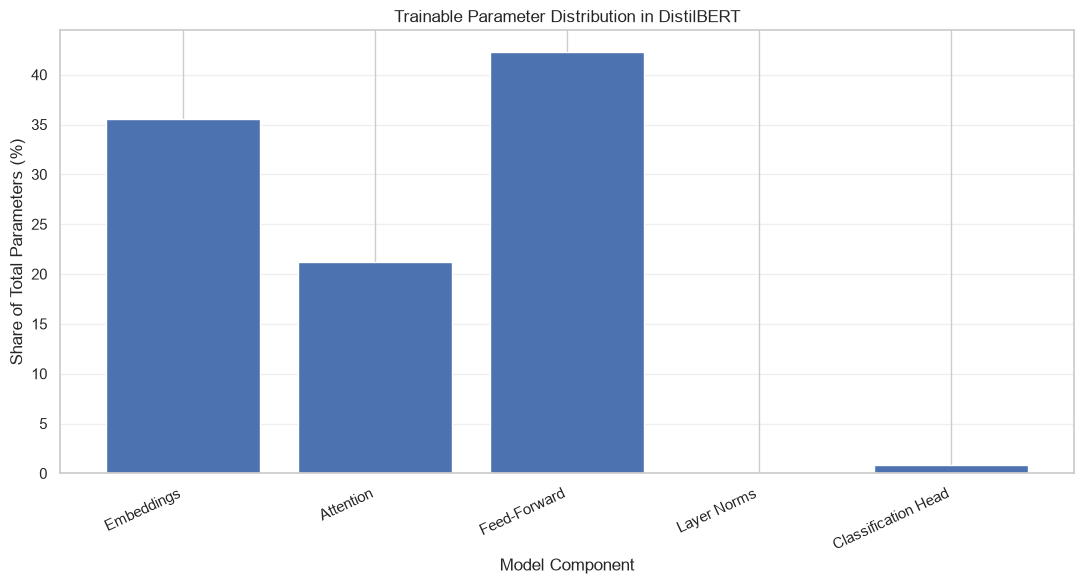

In [73]:
plt.figure(figsize=(11, 6))

plt.bar(
    parameter_table["Component"],
    parameter_table["Percentage (%)"]
)

plt.title("Trainable Parameter Distribution in DistilBERT")
plt.xlabel("Model Component")
plt.ylabel("Share of Total Parameters (%)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 3.4 Use the Encoder with Fill-Mask

## Load the fill-mask pipeline

In [74]:
from transformers import pipeline

fill_mask = pipeline(
    "fill-mask",
    model="distilbert-base-uncased",
    device=-1
)

# Store three sentences containing the mask token
sentences = [
    "The capital of France is [MASK].",
    "The animal did not cross the street because it was too [MASK].",
    "I drink my coffee with [MASK] every morning."
]

for sentence in sentences:
    print("\nSentence:", sentence)

    predictions = fill_mask(sentence, top_k=3)

    # Display each predicted word and its score
    for prediction in predictions:
        print(
            prediction["token_str"],
            "Score:",
            round(prediction["score"], 4)
        )

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Sentence: The capital of France is [MASK].
marseille Score: 0.1427
nantes Score: 0.0902
toulouse Score: 0.0881

Sentence: The animal did not cross the street because it was too [MASK].
dangerous Score: 0.1342
close Score: 0.0487
dark Score: 0.0403

Sentence: I drink my coffee with [MASK] every morning.
him Score: 0.0343
gage Score: 0.015
myself Score: 0.0127


# 4.5: Bidirectional Attention Heatmap
## Extract the last-layer attention

In [75]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

model = AutoModel.from_pretrained(
    "distilbert-base-uncased",
    attn_implementation="eager"
)

model.eval()

sentence = "The animal did not cross the street because it was too tired."

inputs = tokenizer(sentence, return_tensors="pt")

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True,
        return_dict=True
    )

last_layer_attention = outputs.attentions[-1]

average_attention = last_layer_attention.mean(dim=1)

# Select the first item in the batch and convert it to NumPy
attention_matrix = average_attention[0].cpu().numpy()

print("Last-layer attention shape:", attention_matrix.shape)
print("Tokens:", tokens)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Last-layer attention shape: (15, 15)
Tokens: ['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


## Plot the attention heatmap

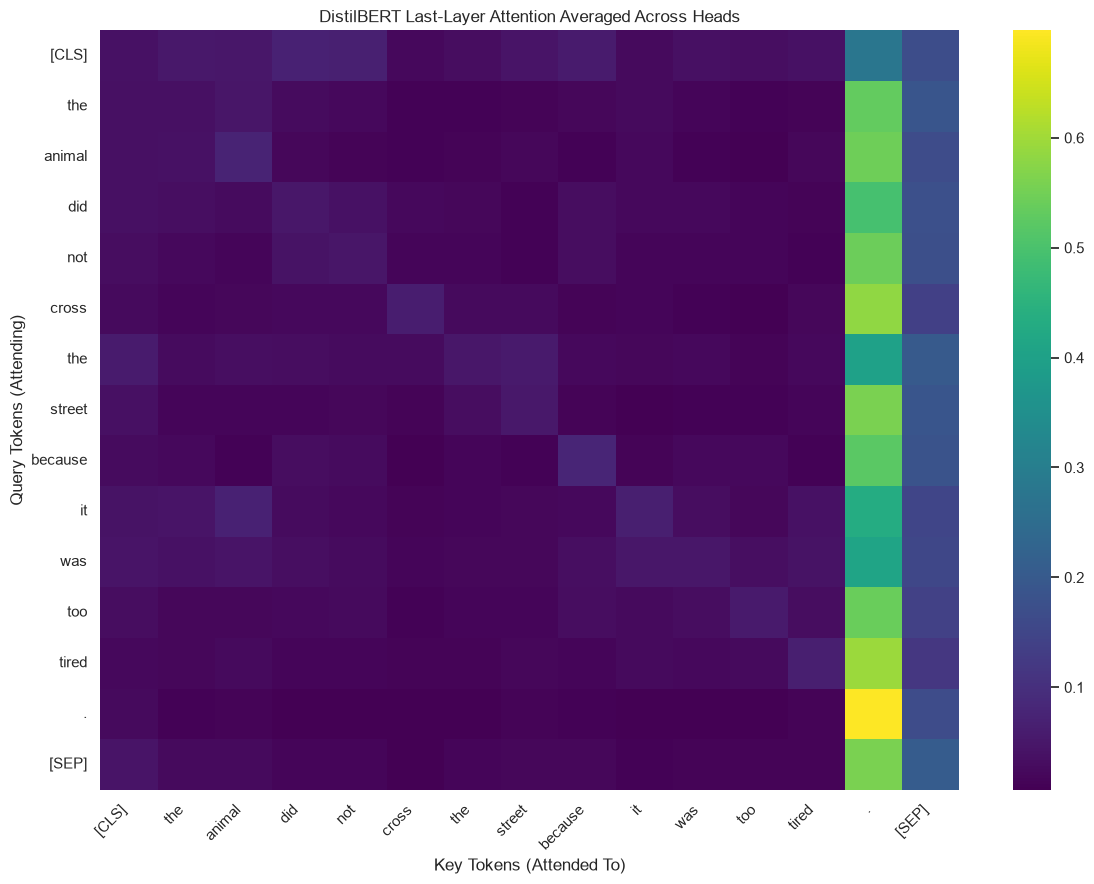

In [76]:
plt.figure(figsize=(12, 9))
sns.heatmap(
    attention_matrix,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("DistilBERT Last-Layer Attention Averaged Across Heads")
plt.xlabel("Key Tokens (Attended To)")
plt.ylabel("Query Tokens (Attending)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Check attention above and below the diagonal

In [77]:
upper_mask = np.triu(
    np.ones_like(attention_matrix, dtype=bool),
    k=1)

lower_mask = np.tril(
    np.ones_like(attention_matrix, dtype=bool),
    k=-1)

upper_values = attention_matrix[upper_mask]

lower_values = attention_matrix[lower_mask]

print("Maximum attention above diagonal:", upper_values.max())
print("Maximum attention below diagonal:", lower_values.max())

print("Positive weights above diagonal:", np.any(upper_values > 0))
print("Positive weights below diagonal:", np.any(lower_values > 0))

Maximum attention above diagonal: 0.5929894
Maximum attention below diagonal: 0.557839
Positive weights above diagonal: True
Positive weights below diagonal: True



## Bidirectional Attention vs Causal Attention

The DistilBERT attention heatmap shows that tokens can attend to tokens both before and after their positions. This allows the encoder to build representations using the full sentence context.

A model that generates text one token at a time, such as GPT-2, must not use future tokens when predicting the next token. It therefore uses a causal attention mask, which blocks attention to future positions and allows attention only to the current and earlier positions.

**Conclusion:** DistilBERT uses bidirectional self-attention for contextual understanding, while autoregressive language models use masked self-attention to prevent access to future tokens during next-token prediction.


# 4.6: Masked (Causal) Self-Attention from Scratch

## Create a causal mask for six tokens

In [78]:
um_tokens = 6

causal_mask = np.full(
    (num_tokens, num_tokens),
    -np.inf
)

causal_mask[np.tril_indices(num_tokens)] = 0.0

print("Causal mask:")
print(causal_mask)

Causal mask:
[[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]


## Apply the mask before softmax

In [79]:
np.random.seed(42)

d_model = 8

X_causal = np.random.randn(num_tokens, d_model)

Wq_causal = np.random.randn(d_model, d_model) * 0.5
Wk_causal = np.random.randn(d_model, d_model) * 0.5

Q_causal = X_causal @ Wq_causal
K_causal = X_causal @ Wk_causal
scores_causal = Q_causal @ K_causal.T

scores_causal = scores_causal / np.sqrt(d_model)

masked_scores = scores_causal + causal_mask

shifted_scores = masked_scores - np.max(
    masked_scores,
    axis=1,
    keepdims=True)

exp_scores = np.exp(shifted_scores)

causal_attention = exp_scores / np.sum(
    exp_scores,
    axis=1,
    keepdims=True)

print("Causal attention matrix:")
print(np.round(causal_attention, 4))

print("\nRow sums:")
print(causal_attention.sum(axis=1).round(6))

print("\nMaximum attention above diagonal:")
print(np.triu(causal_attention, k=1).max())

Causal attention matrix:
[[1.     0.     0.     0.    ]
 [0.9031 0.0969 0.     0.    ]
 [0.7479 0.0637 0.1884 0.    ]
 [0.0951 0.4947 0.1775 0.2327]]

Row sums:
[1. 1. 1. 1.]

Maximum attention above diagonal:
0.0


## Plot the causal attention matrix

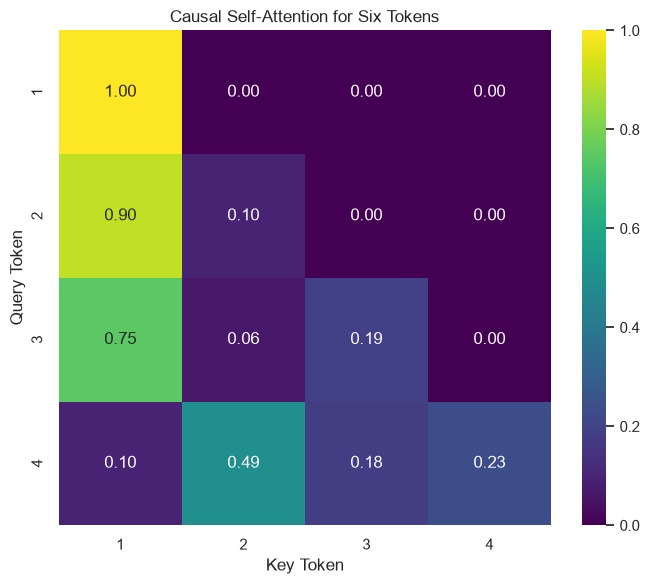

In [80]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    causal_attention,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=range(1, num_tokens + 1),
    yticklabels=range(1, num_tokens + 1),
    vmin=0
)

plt.title("Causal Self-Attention for Six Tokens")
plt.xlabel("Key Token")
plt.ylabel("Query Token")
plt.tight_layout()
plt.show()


## Why Apply the Causal Mask Before Softmax?

The causal mask adds negative infinity to scores for future tokens before softmax. Since the exponential of negative infinity is zero, future tokens receive zero attention probability, while the allowed probabilities are normalized to sum to one.

If we zeroed the future-token weights after softmax without renormalizing the remaining weights, each row would generally sum to less than one. Masking before softmax prevents future tokens from receiving probability in the first place.


# 4.7: Causal Mask in a Real Decoder
## Load GPT-2 and extract attention weights

In [81]:
gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")

gpt2_model = AutoModel.from_pretrained(
    "gpt2",
    attn_implementation="eager")

gpt2_model.eval()

gpt2_sentence = "The animal did not cross the street because it was tired."

gpt2_inputs = gpt2_tokenizer(
    gpt2_sentence,
    return_tensors="pt")

gpt2_tokens = gpt2_tokenizer.convert_ids_to_tokens(
    gpt2_inputs["input_ids"][0])

# Run GPT-2 without gradient tracking
with torch.no_grad():
    gpt2_outputs = gpt2_model(
        **gpt2_inputs,
        output_attentions=True,
        return_dict=True
    )

gpt2_last_attention = gpt2_outputs.attentions[-1]

gpt2_attention = gpt2_last_attention[0, 0].cpu().numpy()

print("GPT-2 attention shape:", gpt2_attention.shape)
print("GPT-2 tokens:", gpt2_tokens)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 attention shape: (12, 12)
GPT-2 tokens: ['The', 'Ġanimal', 'Ġdid', 'Ġnot', 'Ġcross', 'Ġthe', 'Ġstreet', 'Ġbecause', 'Ġit', 'Ġwas', 'Ġtired', '.']


## Verify the causal mask numerically

In [82]:
future_attention = np.triu(gpt2_attention, k=1)

max_future_attention = future_attention.max()

print("Maximum future-token attention:", max_future_attention)

print(
    "Causal mask verified:",
    max_future_attention < 1e-6)

Maximum future-token attention: 0.0
Causal mask verified: True


## Plot GPT-2 attention

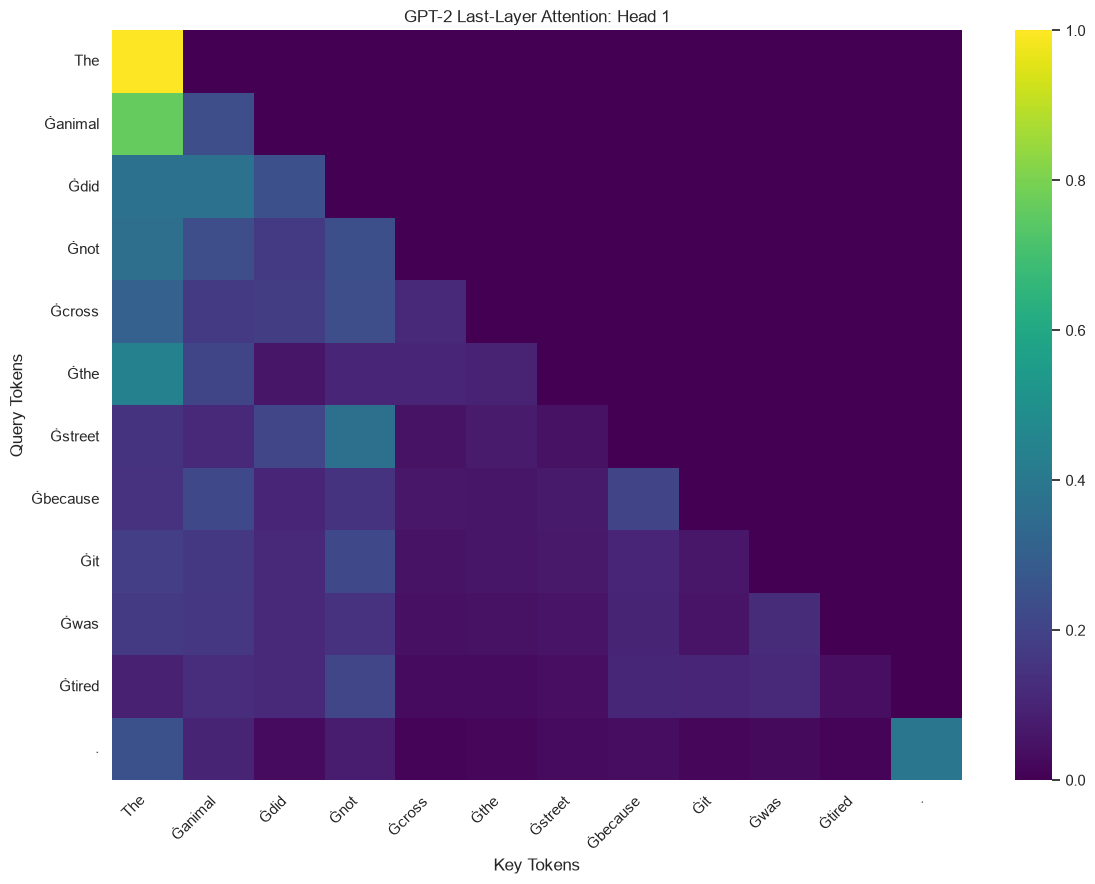

In [83]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    gpt2_attention,
    xticklabels=gpt2_tokens,
    yticklabels=gpt2_tokens,
    cmap="viridis"
)

plt.title("GPT-2 Last-Layer Attention: Head 1")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4.8: Padding Mask vs Causal Mask
## Tokenize two sentences with padding

In [84]:
distilbert_tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased")

distilbert_model = AutoModel.from_pretrained(
    "distilbert-base-uncased",
    attn_implementation="eager"
)

distilbert_model.eval()

batch_sentences = [
    "Cats sleep.",
    "The little cat sleeps on the comfortable sofa."
]

batch_inputs = distilbert_tokenizer(
    batch_sentences,
    padding=True,
    return_tensors="pt"
)

# Print the input IDs
print("Input IDs:")
print(batch_inputs["input_ids"])

# Print the attention mask
print("\nAttention mask:")
print(batch_inputs["attention_mask"])

# Convert token IDs into readable token labels
for sentence_index in range(len(batch_sentences)):

    # Convert this sentence's token IDs into tokens
    batch_tokens = distilbert_tokenizer.convert_ids_to_tokens(
        batch_inputs["input_ids"][sentence_index]
    )

    # Display tokens, including padding tokens
    print(f"\nSentence {sentence_index + 1}:")
    print(batch_tokens)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Input IDs:
tensor([[  101,  8870,  3637,  1012,   102,     0,     0,     0,     0,     0,
             0],
        [  101,  1996,  2210,  4937, 25126,  2006,  1996,  6625, 10682,  1012,
           102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

Sentence 1:
['[CLS]', 'cats', 'sleep', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

Sentence 2:
['[CLS]', 'the', 'little', 'cat', 'sleeps', 'on', 'the', 'comfortable', 'sofa', '.', '[SEP]']


## Extract attention weights

In [85]:
with torch.no_grad():
    batch_outputs = distilbert_model(
        **batch_inputs,
        output_attentions=True,
        return_dict=True
    )

batch_last_attention = batch_outputs.attentions[-1]

batch_average_attention = batch_last_attention.mean(dim=1)

batch_mask = batch_inputs["attention_mask"].cpu().numpy()

pad_token_id = distilbert_tokenizer.pad_token_id

for sentence_index in range(len(batch_sentences)):

    token_ids = batch_inputs["input_ids"][sentence_index]

    padding_positions = (token_ids == pad_token_id).nonzero(as_tuple=True)[0]

    print(f"\nSentence {sentence_index + 1}")

    print("Padding positions:", padding_positions.tolist())

    # Skip the weight check if there are no padding tokens
    if len(padding_positions) > 0:

        weights_to_padding = batch_average_attention[
            sentence_index
        ][:, padding_positions]

        max_padding_weight = weights_to_padding.abs().max().item()

        print("Maximum attention weight to padding keys:",max_padding_weight)

        print(
            "Padding mask verified:",max_padding_weight < 1e-6)
    else:
        print("No padding tokens found.")


Sentence 1
Padding positions: [5, 6, 7, 8, 9, 10]
Maximum attention weight to padding keys: 0.0
Padding mask verified: True

Sentence 2
Padding positions: []
No padding tokens found.


## Plot the padded sentence's attention matrix 

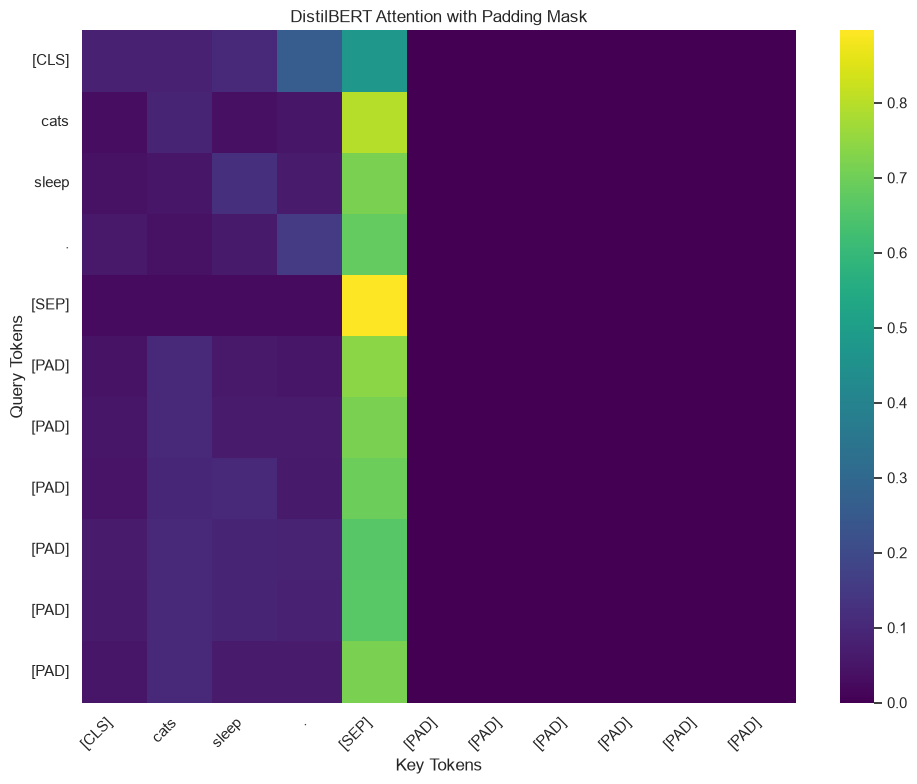

In [86]:
padding_attention = batch_average_attention[0].cpu().numpy()

padding_tokens = distilbert_tokenizer.convert_ids_to_tokens(
    batch_inputs["input_ids"][0])

plt.figure(figsize=(10, 8))

sns.heatmap(
    padding_attention,
    xticklabels=padding_tokens,
    yticklabels=padding_tokens,
    cmap="viridis"
)

plt.title("DistilBERT Attention with Padding Mask")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Padding Mask vs Causal Mask

| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Purpose | Prevents attention to padding tokens | Prevents attention to future tokens |
| Typical pattern | Masks key positions that correspond to padding; the pattern depends on each sequence | Masks positions above the diagonal |
| Common use | Encoder models such as BERT and DistilBERT; also used in decoder models for padding | Autoregressive decoder models such as GPT-2 |
| Main benefit | Prevents artificial padding tokens from influencing valid token representations | Prevents a token from accessing future tokens during next-token prediction |

A padding mask and a causal mask solve different problems. Padding masks ignore artificial tokens added to equalize sequence lengths, whereas causal masks enforce the left-to-right information flow required for autoregressive generation. Some models use both masks together.



# Task 5.1 — Transformer Decoder Architecture

The original Transformer decoder generates the target sequence one token at a time. It contains three main sublayers:

1. **Masked Multi-Head Self-Attention:** Each target token can attend only to previous target tokens and itself. Future tokens are hidden using a causal mask.
2. **Add & Norm:** The attention output is added to the original input through a residual connection and then normalized using Layer Normalization.
3. **Cross-Attention:** The decoder uses its current representations as Queries (Q), while Keys (K) and Values (V) come from the encoder output. This allows the decoder to focus on relevant parts of the source sentence.
4. **Add & Norm:** A residual connection and Layer Normalization are applied after cross-attention.
5. **Feed-Forward Network:** A neural network processes each token representation independently.
6. **Add & Norm:** Another residual connection and Layer Normalization are applied.

After the decoder blocks, a linear layer converts hidden representations into vocabulary scores (logits). Softmax converts these scores into probabilities over the vocabulary. The model selects the next token and continues generating until the output is complete.

## Three Transformer Model Families

- **Encoder-only (BERT / DistilBERT):** Uses encoder blocks with bidirectional self-attention. It is commonly used for classification, sentiment analysis, and understanding text.
- **Decoder-only (GPT-2):** Uses masked self-attention and does not use cross-attention to an encoder. It generates text autoregressively, predicting one token at a time.
- **Encoder-decoder (T5):** Uses an encoder to understand the input and a decoder with masked self-attention and cross-attention to generate an output. It is useful for translation, summarization, and other text-to-text tasks.

**Conclusion:** The encoder understands the input, the decoder generates the output, and an encoder-decoder Transformer combines both capabilities.


# Task 5.2 — Cross-Attention

In cross-attention, the Queries (Q) come from the decoder's current hidden representations, while the Keys (K) and Values (V) come from the encoder output.

This allows the decoder to look back at the source sentence while generating the target sentence. For example, during English-to-French translation, the encoder processes the English sentence. The decoder then uses cross-attention to focus on relevant English words while producing each French word.

Cross-attention is related to Luong attention from Task 2.4. In Luong attention, the decoder hidden state is compared with encoder hidden states to calculate attention scores. These scores determine how much attention each source position receives, and a weighted sum of encoder states provides context for generating the next output.

The main idea is similar in Transformer cross-attention, but Transformers use learned Query, Key, and Value projections and can compute attention across multiple heads in parallel.

**Conclusion:** Cross-attention connects the decoder to the encoder, helping the decoder generate output based on relevant information from the input sentence.


# 5.3 — Run an Encoder-Decoder Model
## Load the translation pipeline

In [ ]:

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

t5_name = "t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained("google-t5/t5-small")

t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    t5_name,
    attn_implementation="eager"
)

t5_model.eval()

print("T5-small model loaded successfully.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Users\Santosh verma\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Santosh verma\.cache\huggingface\hub\models--t5-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small model loaded successfully.


## Translate three English sentences

In [91]:
english_sentences = [
    "Machine learning helps computers learn from data.",
    "The weather is beautiful today.",
    "Education is important for everyone."
]

for sentence in english_sentences:

    translation_input = "translate English to French: " + sentence

    inputs = t5_tokenizer(translation_input,return_tensors="pt")

    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=60
        )

    french_text = t5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    print("English:", sentence)

    print("French:", french_text)
    print()


English: Machine learning helps computers learn from data.
French: L'apprentissage en machine aide les ordinateurs à tirer des enseignements de données.

English: The weather is beautiful today.
French: Le temps est beau aujourd'hui.

English: Education is important for everyone.
French: L'éducation est importante pour tous.



## Prepare a real paragraph for summarization

In [92]:
article_text = """
Artificial intelligence is changing the way people work, learn, and communicate.
Modern AI systems can analyze large amounts of data, recognize patterns, and
help people solve complex problems. In healthcare, AI tools can support doctors
by organizing medical information and assisting with image analysis. In education,
AI-powered applications can provide personalized explanations and help students
practice difficult concepts. Businesses also use AI to automate repetitive tasks,
improve customer service, and make better decisions. However, AI systems can
produce incorrect information and may reflect bias present in their training data.
Privacy, security, transparency, and responsible use are therefore important.
Researchers and organizations continue to develop methods to evaluate AI systems
and make them more reliable. Human supervision remains valuable, especially when
AI is used for important decisions. As the technology advances, people need to
understand both its benefits and its limitations. Education and careful planning
can help society use AI effectively while reducing potential risks.
"""

input_word_count = len(article_text.split())

print("Input length:", input_word_count, "words")

Input length: 154 words


## Generate the summary and count words

In [ ]:
summary_input = "summarize: " + article_text

input_word_count = len(article_text.split())

summary_inputs = t5_tokenizer(
    summary_input,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

with torch.no_grad():
    summary_ids = t5_model.generate(
        **summary_inputs,
        max_length=60,
        min_length=20,
        do_sample=False
    )

summary_text = t5_tokenizer.decode(summary_ids[0],skip_special_tokens=True)

summary_word_count = len(summary_text.split())

print("Generated Summary:")
print(summary_text)

print("\nInput length:", input_word_count, "words")
print("Summary length:", summary_word_count, "words")


Generated Summary:
AI tools can help people solve complex problems. in healthcare, AI tools can help doctors by organizing medical information. businesses also use AI to automate repetitive tasks.

Input length: 154 words
Summary length: 27 words


# 5.4 — Extract and Plot Cross-Attention
## Load T5 model

In [ ]:
from transformers import T5ForConditionalGeneration, T5Tokenizer

t5_tokenizer = T5Tokenizer.from_pretrained("t5-small")

t5_model = T5ForConditionalGeneration.from_pretrained(
    "t5-small",
    attn_implementation="eager"
)

t5_model = t5_model.to("cpu")

t5_model.eval()

## Tokenize the input and expected output

In [ ]:
input_text = "translate English to French: The house is small."

target_text = "La maison est petite."

input_encoding = t5_tokenizer(
    input_text,
    return_tensors="pt"
)

label_encoding = t5_tokenizer(
    text_target=target_text,
    return_tensors="pt"
)

print("Input tokens:")
print(t5_tokenizer.convert_ids_to_tokens(input_encoding["input_ids"][0]))

print("\nTarget tokens:")
print(t5_tokenizer.convert_ids_to_tokens(label_encoding["input_ids"][0]))

print("\nInput shape:", input_encoding["input_ids"].shape)

print("Label shape:", label_encoding["input_ids"].shape)

## Extract cross-attention weights

In [ ]:
# Run the model without calculating gradients
with torch.no_grad():

    outputs = t5_model(
        input_ids=input_encoding["input_ids"],
        attention_mask=input_encoding["attention_mask"],
        labels=label_encoding["input_ids"],
        output_attentions=True,
        return_dict=True
    )

cross_attentions = outputs.cross_attentions

last_cross_attention = cross_attentions[-1]

average_cross_attention = last_cross_attention.mean(dim=1)

attention_matrix = average_cross_attention[0].cpu().numpy()

print("Last layer attention shape:", last_cross_attention.shape)

print("Average attention matrix shape:", attention_matrix.shape)



## Cross-Attention Analysis

The heatmap displays the cross-attention weights from the last decoder layer, averaged across its eight attention heads. The rows represent French output tokens, and the columns represent English input tokens.

A larger attention weight indicates that an output token places more attention on a particular input token. We can inspect whether French words attend to related English words. For example, the French token `maison` may attend strongly to the English word `house`, while `petite` may attend to `small`.

This alignment is not necessarily one-to-one. Attention can be distributed across multiple words, punctuation, and task-prefix tokens. Different heads and decoder layers may also learn different relationships.

**Conclusion:** Cross-attention helps T5 use information from the English input while generating the French translation. The heatmap provides a visual way to investigate these relationships.


# 5.5 — Autoregressive Decoding
## Load GPT-2

In [96]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

gpt2_tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

gpt2_model = GPT2LMHeadModel.from_pretrained(
    "gpt2",
    attn_implementation="eager")

gpt2_model = gpt2_model.to("cpu")

gpt2_model.eval()

gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token

print("GPT-2 model loaded successfully.")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 model loaded successfully.


C:\Users\Santosh verma\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Santosh verma\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## Tokenize the starting prompt

In [97]:
prompt = "Artificial intelligence will"

input_ids = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

print("Starting prompt:", prompt)

print("Input IDs:", input_ids)

print("Input shape:", input_ids.shape)

Starting prompt: Artificial intelligence will
Input IDs: tensor([[8001, 9542, 4430,  481]])
Input shape: torch.Size([1, 4])


## Write the manual greedy decoding loop

In [98]:
manual_input_ids = input_ids.clone()

with torch.no_grad():

    for step in range(20):

        outputs = gpt2_model(input_ids=manual_input_ids)

        next_token_logits = outputs.logits[:, -1, :]

        next_token_id = torch.argmax(
            next_token_logits,
            dim=-1,
            keepdim=True
        )

        manual_input_ids = torch.cat(
            [manual_input_ids, next_token_id],
            dim=1
        )

manual_text = gpt2_tokenizer.decode(
    manual_input_ids[0],
    skip_special_tokens=True
)

print("Manual greedy decoding output:")
print(manual_text)

Manual greedy decoding output:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


## Compare against model.generate()

In [99]:
with torch.no_grad():

    generated_ids = gpt2_model.generate(
        input_ids=input_ids,
        max_new_tokens=20,
        do_sample=False,
        num_beams=1,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generated_text = gpt2_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True)

print("Built-in generate() output:")
print(generated_text)

tokens_identical = torch.equal(
    manual_input_ids,
    generated_ids)

print("\nAre the token sequences identical?", tokens_identical)

print("Are the decoded texts identical?", manual_text == generated_text)

Built-in generate() output:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Are the token sequences identical? True
Are the decoded texts identical? True


# 5.6 — Decoding Strategies
## Generate outputs

In [100]:
import random

prompt = "Artificial intelligence will"

# Convert the prompt into token IDs
input_ids = gpt2_tokenizer(prompt, return_tensors="pt")["input_ids"]

# Store every generated output in a dictionary
decoding_results = {}

# Use evaluation mode
gpt2_model.eval()

# 1. Greedy decoding: always select the highest-scoring next token
with torch.no_grad():
    greedy_ids = gpt2_model.generate(
        input_ids=input_ids,
        max_new_tokens=40,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

# Save the decoded greedy output
decoding_results["Greedy"] = gpt2_tokenizer.decode(
    greedy_ids[0], skip_special_tokens=True
)

# 2. Beam search: keep the five best candidate sequences
with torch.no_grad():
    beam_ids = gpt2_model.generate(
        input_ids=input_ids,
        max_new_tokens=40,
        num_beams=5,
        early_stopping=True,
        do_sample=False,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

# Save the decoded beam-search output
decoding_results["Beam Search (5 beams)"] = gpt2_tokenizer.decode(
    beam_ids[0], skip_special_tokens=True
)

# 3 and 4. Sampling with two temperatures and two random seeds
for temperature in [0.7, 1.5]:

    # Try two different seeds for each temperature
    for seed in [42, 123]:

        # Set seeds so the experiment can be repeated
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        # Generate tokens by sampling from the temperature-scaled distribution
        with torch.no_grad():
            sampled_ids = gpt2_model.generate(
                input_ids=input_ids,
                max_new_tokens=40,
                do_sample=True,
                temperature=temperature,
                use_cache=True,
                pad_token_id=gpt2_tokenizer.eos_token_id
            )

        # Save each output with its temperature and seed
        result_name = f"Temperature {temperature}, seed {seed}"
        decoding_results[result_name] = gpt2_tokenizer.decode(
            sampled_ids[0], skip_special_tokens=True
        )

# 5. Top-k and top-p sampling together
# Reset the random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Generate tokens using top-k and nucleus (top-p) sampling
with torch.no_grad():
    top_k_top_p_ids = gpt2_model.generate(
        input_ids=input_ids,
        max_new_tokens=40,
        do_sample=True,
        top_k=50,
        top_p=0.9,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

# Save the decoded output
decoding_results["Top-k 50 + Top-p 0.9"] = gpt2_tokenizer.decode(
    top_k_top_p_ids[0], skip_special_tokens=True
)

# Print the number of generated results
print("Total decoding outputs:", len(decoding_results))


Total decoding outputs: 7


## Present the five strategies and their outputs in a table

In [ ]:
decoding_table = pd.DataFrame(
    list(decoding_results.items()),
    columns=["Decoding Strategy", "Generated Output"]
)

pd.set_option("display.max_colwidth", None)

display(decoding_table)

,Decoding Strategy,Generated Output
0,Greedy,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.\n\n""We're going to be able to"
1,Beam Search (5 beams),"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.\n\n""I think it's going to take a lot of work to get there,"" he said"
2,"Temperature 0.7, seed 42","Artificial intelligence will be used to create artificial intelligence in the future, but it is not yet a fully mature technology. For example, there is no commercial use of artificial intelligence in the United States. The United States is"
3,"Temperature 0.7, seed 123","Artificial intelligence will not only reduce the speed of our daily lives, but also the way we think and behave. This enables us to adapt our lives to change our thinking, so that we will be able to think with"
4,"Temperature 1.5, seed 42","Artificial intelligence will continue to expand a billion ways in just the near future, experts warn, and new tech could help it. The technology is the most widely studied because it looks what you'd describe as a completely separate"
5,"Temperature 1.5, seed 123","Artificial intelligence will not only reduce the speed of its process by up to 70%, but by at least 20%. This enables us to provide more targeted targeting towards our patients through this technique rather than targeting that much too late"
6,Top-k 50 + Top-p 0.9,"Artificial intelligence will continue to expand to create new types of AI, but it is still hard to see how we can make an AI that is completely compatible with artificial intelligence. In fact, even if we made an AI"



##  Decoding Strategies

- **Greedy decoding:** Selects the highest-probability next token at every step. It is deterministic but can produce repetitive or predictable text.
- **Beam search:** Keeps multiple candidate sequences and selects a high-scoring sequence. It often produces more consistent text, but may still sound generic or repetitive.
- **Temperature = 0.7:** Makes the probability distribution sharper, favouring higher-probability tokens. This usually makes outputs less random.
- **Temperature = 1.5:** Makes the probability distribution flatter, giving lower-probability tokens more opportunities to be selected. This increases randomness and can reduce coherence.
- **Top-k = 50:** Restricts sampling to the 50 highest-scoring candidate tokens.
- **Top-p = 0.9:** Restricts sampling to the smallest group of high-probability tokens whose cumulative probability reaches the selected threshold. The group size changes with the probability distribution.

Temperature controls how sharply probabilities are distributed, while top-k and top-p restrict which tokens may be sampled. These settings affect diversity and coherence, but none guarantees that repetition will disappear.

The two seeds for each temperature demonstrate how sampling can produce different outputs under the same settings. Exact results may vary across library versions and hardware.

**Conclusion:** Greedy decoding is predictable, beam search considers multiple candidate sequences, and sampling methods allow more variation in generated text.


# 5.7 — KV-Cache Speed-up
## Measure generation time

In [106]:
import time

benchmark_prompt = (
    "Artificial intelligence and machine learning "
    "are important technologies"
)

benchmark_inputs = gpt2_tokenizer(benchmark_prompt,return_tensors="pt")

gpt2_model = gpt2_model.to("cpu")
gpt2_model.eval()

def benchmark_generation(use_cache, repetitions=3):

    elapsed_times = []

    for run_number in range(repetitions):

        start_time = time.perf_counter()

        with torch.no_grad():

            output_ids = gpt2_model.generate(
                **benchmark_inputs,
                max_new_tokens=100,
                do_sample=False,
                num_beams=1,
                use_cache=use_cache,
                pad_token_id=gpt2_tokenizer.eos_token_id
            )

        elapsed = time.perf_counter() - start_time

        elapsed_times.append(elapsed)

        output_tokens = (
            output_ids.shape[1]
            - benchmark_inputs["input_ids"].shape[1]
        )

        print(
            f"use_cache={use_cache}, "
            f"run={run_number + 1}, "
            f"time={elapsed:.3f} seconds, "
            f"output_tokens={output_tokens}"
        )

    return elapsed_times


print("Benchmark with cache:")

times_with_cache = benchmark_generation(
    use_cache=True,
    repetitions=3
)

print("\nBenchmark without cache:")

times_without_cache = benchmark_generation(
    use_cache=False,
    repetitions=3
)

Benchmark with cache:
use_cache=True, run=1, time=3.414 seconds, output_tokens=100
use_cache=True, run=2, time=3.009 seconds, output_tokens=100
use_cache=True, run=3, time=3.100 seconds, output_tokens=100

Benchmark without cache:
use_cache=False, run=1, time=6.734 seconds, output_tokens=100
use_cache=False, run=2, time=7.680 seconds, output_tokens=100
use_cache=False, run=3, time=8.318 seconds, output_tokens=100


## Calculate average time and speed-up

In [107]:
average_with_cache = sum(times_with_cache) / len(times_with_cache)

average_without_cache = sum(times_without_cache) / len(times_without_cache)

speed_up = average_without_cache / average_with_cache

print("Average time with cache:",
      round(average_with_cache, 3), "seconds")

print("Average time without cache:",
      round(average_without_cache, 3), "seconds")

print("KV-cache speed-up:",
      round(speed_up, 2), "x")

Average time with cache: 3.174 seconds
Average time without cache: 7.577 seconds
KV-cache speed-up: 2.39 x


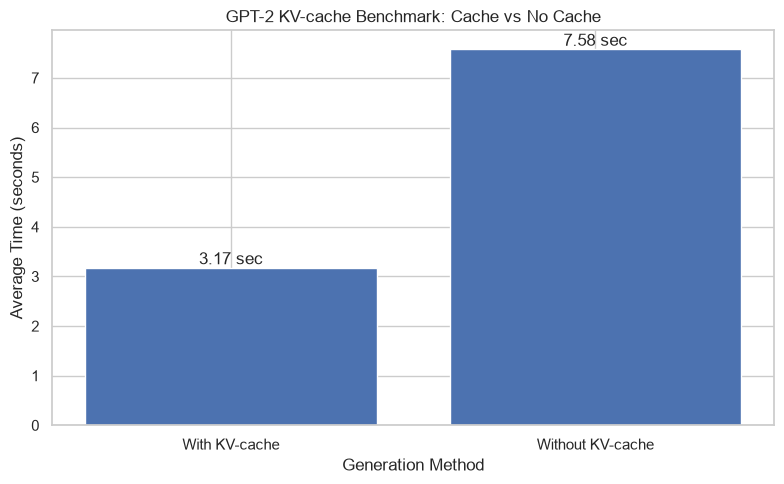

In [110]:
method_names = ["With KV-cache", "Without KV-cache"]

average_times = [
    average_with_cache,
    average_without_cache
]

plt.figure(figsize=(8, 5))

bars = plt.bar(method_names, average_times)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f} sec",
        ha="center",
        va="bottom"
    )

plt.title("GPT-2 KV-cache Benchmark: Cache vs No Cache")
plt.xlabel("Generation Method")
plt.ylabel("Average Time (seconds)")
plt.tight_layout()
plt.show()



##  KV-Cache Speed-up

The KV-cache stores the Key and Value vectors calculated for previously processed tokens. During autoregressive generation, these vectors do not need to be recomputed for every new token.

With `use_cache=True`, GPT-2 reuses the stored Key and Value vectors, reducing repeated computation. With `use_cache=False`, previous tokens must be processed again at each generation step, which generally increases computation time.

The average generation time was measured over three runs for each configuration. The speed-up ratio was calculated by dividing the average time without caching by the average time with caching.

**Conclusion:** KV-caching is an important inference optimization for autoregressive Transformers because it avoids repeatedly calculating attention information for earlier tokens.



# Task 5.8 — Comparison of Transformer Model Families

| Model | Family | Attention Type(s) Used | Can It Generate Text? | Position Scheme | Typical Tasks | Example from This Notebook |
|---|---|---|---|---|---|---|
| DistilBERT | Encoder-only | Bidirectional self-attention | Not as a standard autoregressive text generator; it can support task-specific outputs | Learned absolute positional embeddings | Sentiment analysis, text classification, masked-token prediction | DistilBERT attention heatmap and fill-mask pipeline |
| GPT-2 | Decoder-only | Causal (masked) self-attention | Yes, autoregressively | Learned absolute positional embeddings | Text completion, story generation, next-token prediction | Manual greedy decoding, decoding strategies, and KV-cache timing |
| T5-small | Encoder-decoder | Bidirectional encoder self-attention, causal decoder self-attention, and encoder-decoder cross-attention | Yes | Relative position biases in attention | Translation, summarization, text-to-text tasks | English-to-French translation, summarization, and cross-attention heatmap |

## Key Observations

1. **DistilBERT** is designed mainly to understand input text. Its encoder can attend to tokens on both sides of a position.
2. **GPT-2** generates text one token at a time. Causal attention prevents it from using future tokens when predicting the next token.
3. **T5-small** uses an encoder to process the input and a decoder to generate the output. Cross-attention connects the decoder to the encoder representations.

**Final Conclusion:** The three model families use different attention patterns and positional schemes because they are designed for different tasks. Encoder-only models are useful for understanding text, decoder-only models for text generation, and encoder-decoder models for transforming one text sequence into another.


# 6.1 — Evaluate the Pretrained Sentiment Model

In [124]:
from datasets import load_dataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

device = 0 if torch.cuda.is_available() else -1

print("Using device:", "GPU" if device == 0 else "CPU")

Using device: CPU


## Load the 200 IMDB reviews

In [126]:
imdb_dataset = load_dataset(
    "stanfordnlp/imdb",
    split="test"
)

## Dataset Reviews

In [128]:
imdb_sample = imdb_dataset.shuffle(seed=42).select(range(200))

reviews = imdb_sample["text"]

y_true = imdb_sample["label"]

# Print basic dataset information
print("Number of reviews:", len(reviews))
print("\nFirst review:\n", reviews[0])
print("\nFirst five labels:", y_true[:5])

# Count the positive and negative reviews
print("\nSentiment counts:")
print(imdb_sample.features["label"].names)
print(pd.Series(y_true).value_counts().sort_index())


Number of reviews: 200

First review:
 <br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I started crying and couldn't stop until long after the movie ended. Thank you Jane, Laura and Jocelyn, for bringing us such a wonderfully subtle and compassionate movie! Thank you cast, for being involved and portraying the characters with such depth and gentleness!<br /><br />I recognized the Angry sister; the Runaway sister and the sister in Denial. I recognized the Abusive Husband and why he was there and then the Father, oh oh the Father... all superbly played. I also recognized myself and this movie was an eye-opener, a relief, a chance to face my OWN truth and finally doing something about it. I truly hope A Thousand Acres has had the same effect on s

## Load the pretrained sentiment model

In [129]:
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=-1
)

# Load the matching tokenizer
sentiment_tokenizer = AutoTokenizer.from_pretrained(
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

# Confirm that the model is ready
print("Pretrained sentiment model loaded successfully.")
print("No training or fine-tuning is performed in this task.")


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

C:\Users\Santosh verma\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Santosh verma\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Pretrained sentiment model loaded successfully.
No training or fine-tuning is performed in this task.


## Check Review Format

In [ ]:
reviews = [str(review) for review in reviews]

reviews = [review for review in reviews if review.strip()]

print("Number of valid reviews:", len(reviews))
print("Type of reviews:", type(reviews))
print("Type of first review:", type(reviews[0]))


Number of valid reviews: 200
Type of reviews: <class 'list'>
Type of first review: <class 'str'>


## Evaluate all reviews

In [135]:
start_time = time.perf_counter()

# Predict sentiment for all 200 reviews
predictions_512 = sentiment_pipeline(
    reviews,
    batch_size=16,
    truncation=True,
    max_length=512
)

# Calculate the time taken
time_512 = time.perf_counter() - start_time

# Print the results
print("Total predictions:", len(predictions_512))
print("Time taken:", round(time_512, 2), "seconds")
print("First three predictions:", predictions_512[:3])

Total predictions: 200
Time taken: 40.27 seconds
First three predictions: [{'label': 'POSITIVE', 'score': 0.9988757967948914}, {'label': 'POSITIVE', 'score': 0.9969831109046936}, {'label': 'NEGATIVE', 'score': 0.9972442388534546}]


In [136]:
y_pred_512 = [
    1 if prediction["label"].upper() == "POSITIVE" else 0
    for prediction in predictions_512
]

accuracy_512 = accuracy_score(y_true, y_pred_512)

precision_512 = precision_score(y_true, y_pred_512, zero_division=0)

recall_512 = recall_score(y_true, y_pred_512, zero_division=0)

f1_512 = f1_score(y_true, y_pred_512, zero_division=0)

# Print all evaluation metrics
print("Evaluation at max_length = 512")
print("Accuracy :", round(accuracy_512, 4))
print("Precision:", round(precision_512, 4))
print("Recall   :", round(recall_512, 4))
print("F1 Score :", round(f1_512, 4))
print("Time     :", round(time_512, 2), "seconds")

Evaluation at max_length = 512
Accuracy : 0.87
Precision: 0.8889
Recall   : 0.8333
F1 Score : 0.8602
Time     : 40.27 seconds


## Plot Confusion Matrix

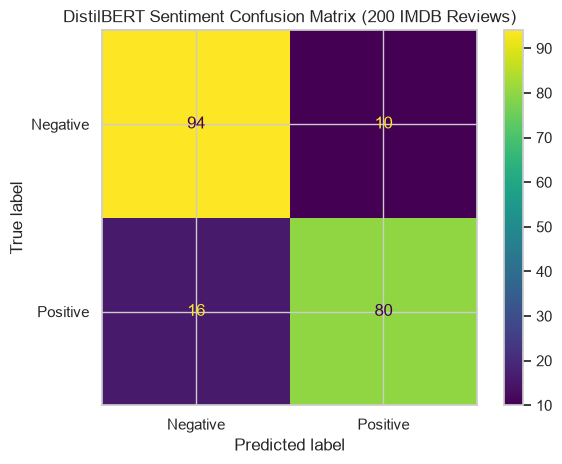

In [137]:
cm_512 = confusion_matrix(
    y_true,
    y_pred_512,
    labels=[0, 1]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_512,
    display_labels=["Negative", "Positive"]
)

cm_display.plot()

plt.title("DistilBERT Sentiment Confusion Matrix (200 IMDB Reviews)")
plt.tight_layout()
plt.show()

# 6.2: Evaluate four truncation lengths

In [138]:
max_lengths = [64, 128, 256, 512]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []
time_values = []

for max_len in max_lengths:

    start_time = time.perf_counter()

    predictions = sentiment_pipeline(
        reviews,
        batch_size=16,
        truncation=True,
        max_length=max_len
    )

    elapsed_time = time.perf_counter() - start_time

    y_pred = [
        1 if prediction["label"].upper() == "POSITIVE" else 0
        for prediction in predictions
    ]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred, zero_division=0)

    recall = recall_score(y_true, y_pred, zero_division=0)

    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Save the results
    accuracy_values.append(accuracy)
    precision_values.append(precision)
    recall_values.append(recall)
    f1_values.append(f1)
    time_values.append(elapsed_time)

    # Print the result for this maximum length
    print("Max length:", max_len)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("Time     :", round(elapsed_time, 2), "seconds")
    print("-" * 35)


Max length: 64
Accuracy : 0.75
Precision: 0.7674
Recall   : 0.6875
F1 Score : 0.7253
Time     : 5.65 seconds
-----------------------------------
Max length: 128
Accuracy : 0.775
Precision: 0.7576
Recall   : 0.7812
F1 Score : 0.7692
Time     : 11.13 seconds
-----------------------------------
Max length: 256
Accuracy : 0.84
Precision: 0.8636
Recall   : 0.7917
F1 Score : 0.8261
Time     : 22.11 seconds
-----------------------------------
Max length: 512
Accuracy : 0.87
Precision: 0.8889
Recall   : 0.8333
F1 Score : 0.8602
Time     : 41.69 seconds
-----------------------------------


## Create the results table

In [139]:
results_df = pd.DataFrame({
    "Max Length": max_lengths,
    "Accuracy": accuracy_values,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1 Score": f1_values,
    "Time (seconds)": time_values
})

display(results_df.round(4))


,Max Length,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,64,0.750,0.7674,0.6875,0.7253,5.6495
1,128,0.775,0.7576,0.7812,0.7692,11.1283
2,256,0.840,0.8636,0.7917,0.8261,22.1056
3,512,0.870,0.8889,0.8333,0.8602,41.6927


## Plot accuracy against maximum length

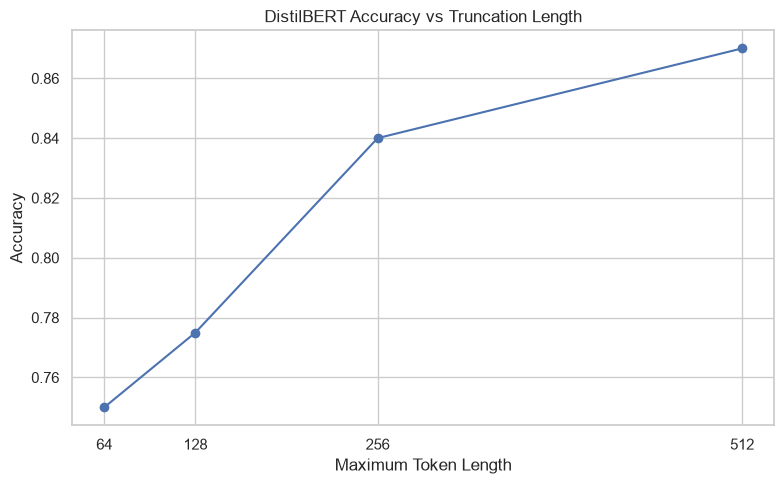

In [140]:
plt.figure(figsize=(8, 5))

plt.plot(
    max_lengths,
    accuracy_values,
    marker="o"
)

plt.title("DistilBERT Accuracy vs Truncation Length")

plt.xlabel("Maximum Token Length")
plt.ylabel("Accuracy")
plt.xticks(max_lengths)
plt.grid(True)

plt.tight_layout()
plt.show()


## Count reviews longer than 512 tokens

In [142]:
review_token_lengths = []

for review in reviews:

    token_ids = sentiment_tokenizer.encode(
        review,
        add_special_tokens=True,
        truncation=False
    )

    review_token_lengths.append(len(token_ids))

reviews_over_512 = sum(
    length > 512
    for length in review_token_lengths
)

longest_review = max(review_token_lengths)

print("Total reviews:", len(reviews))
print("Reviews exceeding 512 tokens:", reviews_over_512)
print("Longest review token count:", longest_review)

for max_len in max_lengths:

    count_over_limit = sum(
        length > max_len
        for length in review_token_lengths
    )

    print(
        "\nReviews exceeding",
        max_len,
        "tokens:",
        count_over_limit
    )


Total reviews: 200
Reviews exceeding 512 tokens: 18
Longest review token count: 1453

Reviews exceeding 64 tokens: 196

Reviews exceeding 128 tokens: 172

Reviews exceeding 256 tokens: 71

Reviews exceeding 512 tokens: 18


## Calculate accuracy loss and time difference

In [143]:
accuracy_64 = accuracy_values[max_lengths.index(64)]
accuracy_512 = accuracy_values[max_lengths.index(512)]

accuracy_loss = (accuracy_512 - accuracy_64) * 100

time_64 = time_values[max_lengths.index(64)]
time_512 = time_values[max_lengths.index(512)]

additional_time = time_512 - time_64

print("Accuracy at 64 tokens :", round(accuracy_64 * 100, 2), "%")
print("Accuracy at 512 tokens:", round(accuracy_512 * 100, 2), "%")

print(
    "Accuracy change (512 minus 64):",
    round(accuracy_loss, 2),
    "percentage points"
)

print("Time at 64 tokens :", round(time_64, 2), "seconds")
print("Time at 512 tokens:", round(time_512, 2), "seconds")

print(
    "Additional time at 512 tokens:",
    round(additional_time, 2),
    "seconds"
)


Accuracy at 64 tokens : 75.0 %
Accuracy at 512 tokens: 87.0 %
Accuracy change (512 minus 64): 12.0 percentage points
Time at 64 tokens : 5.65 seconds
Time at 512 tokens: 41.69 seconds
Additional time at 512 tokens: 36.04 seconds


# 6.3 — Cost Grows with Sequence Length
## Prepare the model and test inputs

In [144]:
sentiment_pipeline.model = sentiment_pipeline.model.to("cpu")

sentiment_pipeline.model.eval()

benchmark_tokenizer = sentiment_pipeline.tokenizer

benchmark_text = (
    "Artificial intelligence and machine learning are changing "
    "the way people work, learn, communicate, and solve problems. "
)

sequence_lengths = [32, 64, 128, 256, 512]

sequence_benchmark_results = []

print("Benchmark device: CPU")
print("Sequence lengths:", sequence_lengths)

Benchmark device: CPU
Sequence lengths: [32, 64, 128, 256, 512]


## Measure forward-pass time

In [ ]:
for seq_len in sequence_lengths:

    repeated_text = benchmark_text * (seq_len // 10 + 5)

    encoded = benchmark_tokenizer(
        repeated_text,
        max_length=seq_len,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    )

    model_inputs = {
        "input_ids": encoded["input_ids"],
        "attention_mask": encoded["attention_mask"]
    }

    with torch.no_grad():
        _ = sentiment_pipeline.model(**model_inputs)

    run_times = []

    for run_number in range(10):

        start_time = time.perf_counter()

        with torch.no_grad():
            _ = sentiment_pipeline.model(**model_inputs)

        elapsed_time = time.perf_counter() - start_time

        run_times.append(elapsed_time * 1000)

    average_time_ms = sum(run_times) / len(run_times)

    sequence_benchmark_results.append({
        "Sequence Length": seq_len,
        "Average Time (ms)": average_time_ms
    })

    print(
        f"Length={seq_len:3d} tokens | "
        f"Average={average_time_ms:.3f} ms"
    )

sequence_benchmark_df = pd.DataFrame(sequence_benchmark_results)

display(sequence_benchmark_df.round(3))


Length= 32 tokens | Average=25.945 ms
Length= 64 tokens | Average=48.777 ms
Length=128 tokens | Average=88.088 ms
Length=256 tokens | Average=140.644 ms
Length=512 tokens | Average=277.761 ms


,Sequence Length,Average Time (ms)
0,32,25.945
1,64,48.777
2,128,88.088
3,256,140.644
4,512,277.761


## Plot time against sequence length

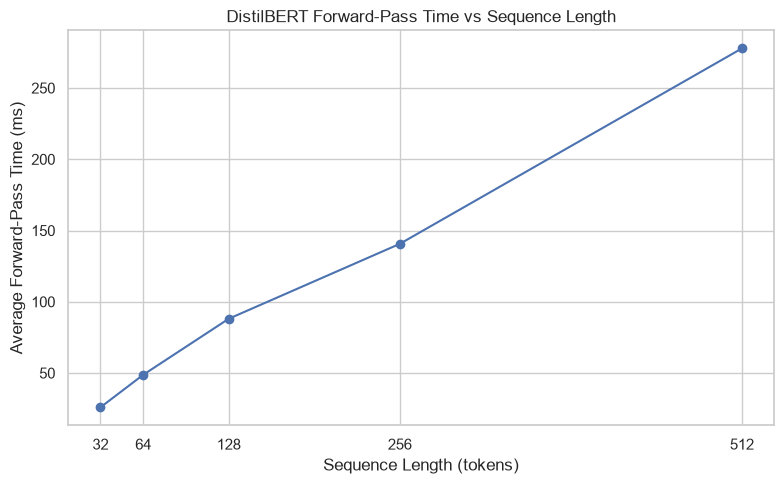

In [146]:

# Create a figure
plt.figure(figsize=(8, 5))

# Plot sequence length against average forward-pass time
plt.plot(
    sequence_benchmark_df["Sequence Length"],
    sequence_benchmark_df["Average Time (ms)"],
    marker="o"
)

# Add chart title and axis labels
plt.title("DistilBERT Forward-Pass Time vs Sequence Length")
plt.xlabel("Sequence Length (tokens)")
plt.ylabel("Average Forward-Pass Time (ms)")

# Display the tested sequence lengths on the x-axis
plt.xticks(sequence_lengths)

# Add a grid
plt.grid(True)

# Adjust the layout
plt.tight_layout()

# Display the plot
plt.show()



## Sequence Length and Computational Cost

The forward-pass time of DistilBERT was measured for input lengths of 32, 64, 128, 256, and 512 tokens. Each measurement is the average of 10 runs after one warm-up run on the CPU.

In standard self-attention, every token can compare its representation with every other token. Therefore, the attention score matrix has a size proportional to the square of the sequence length, giving the attention computation an approximate O(n²) cost with respect to sequence length.

For example, increasing the sequence length from 256 to 512 doubles the number of tokens and increases the number of pairwise attention positions by approximately four times. However, total model runtime also includes embedding, feed-forward, and other operations, so measured time does not necessarily grow exactly quadratically.

The model's 512-token input limit also restricts how much of a long review can be processed in one forward pass. Text beyond this limit is truncated in this experiment.

**Measurement limitation:** Small CPU benchmarks can look closer to linear because fixed overhead, feed-forward operations, memory behavior, and measurement noise affect the observed time. The plotted measurements should be used to describe the actual trend on this computer.

**Conclusion:** Longer sequences increase computational cost, and the 512-token context limit represents a practical trade-off between input coverage and inference cost.


# 6.4 — Hallucination Check with GPT-2

In [147]:
fact_prompts = [
    "The capital of Australia is",
    "The author of the novel Pride and Prejudice is",
    "The inventor of the telephone was"
]

# Display the prompts
for prompt in fact_prompts:
    print(prompt)


The capital of Australia is
The author of the novel Pride and Prejudice is
The inventor of the telephone was


## Generate 30 tokens with greedy decoding

In [ ]:
gpt2_model.eval()

fact_results = []

with torch.no_grad():

    for prompt in fact_prompts:

        prompt_inputs = gpt2_tokenizer(
            prompt,
            return_tensors="pt"
        )

        generated_ids = gpt2_model.generate(
            input_ids=prompt_inputs["input_ids"],
            attention_mask=prompt_inputs["attention_mask"],
            max_new_tokens=30,
            do_sample=False,
            num_beams=1,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

        generated_text = gpt2_tokenizer.decode(
            generated_ids[0],
            skip_special_tokens=True
        )

        fact_results.append({
            "Prompt": prompt,
            "Generated Output": generated_text
        })

        print("Prompt:", prompt)
        print("GPT-2 output:", generated_text)
        print(

Prompt: The capital of Australia is
GPT-2 output: The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest

Prompt: The author of the novel Pride and Prejudice is
GPT-2 output: The author of the novel Pride and Prejudice is a former member of the National Security Council.

The author of the novel is a former member of the National Security Council.

The author

Prompt: The inventor of the telephone was
GPT-2 output: The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who



## Evaluate the generated outputs

In [ ]:
fact_review_df = pd.DataFrame(fact_results)

fact_review_df["Evaluation"] = [
    "Partly correct",
    "Partly correct",
    "Partly correct"
]

display(fact_review_df)

,Prompt,Generated Output,Evaluation
0,The capital of Australia is,"The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.\n\nThe coal industry is also the world's largest",Partly correct
1,The author of the novel Pride and Prejudice is,The author of the novel Pride and Prejudice is a former member of the National Security Council.\n\nThe author of the novel is a former member of the National Security Council.\n\nThe author,Partly correct
2,The inventor of the telephone was,The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who,Partly correct


# 6.5 — Build the mini application

##  Build a Mini Transformer Text Toolkit

**Objective:** Create a reusable `text_toolkit(text)` function that uses pretrained Transformer models to perform three tasks:

1. Sentiment analysis using DistilBERT.
2. Text summarization using T5-small.
3. French translation of the generated summary using T5-small.

The function will handle empty inputs and truncate very long inputs. Finally, it will be tested on three passages and the outputs will be displayed in a pandas DataFrame.


## check model exist

In [ ]:
print("Sentiment model available:", "sentiment_pipeline" in globals())

print("T5 model available:", "t5_model" in globals())

print("T5 tokenizer available:", "t5_tokenizer" in globals())

Sentiment model available: True
T5 model available: True
T5 tokenizer available: True


## Create the text_toolkit() function

In [151]:
def text_toolkit(text):

    if not isinstance(text, str) or not text.strip():
        return {
            "Sentiment Label": "Not available",
            "Sentiment Score": None,
            "Summary": "No text provided.",
            "French Translation": "Aucun texte fourni.",
            "Message": "Please provide non-empty text."
        }

    text = text.strip()
    words = text.split()
    was_truncated = len(words) > 400

    if was_truncated: text = " ".join(words[:400])

    # 1. Sentiment analysis using DistilBERT
    sentiment_result = sentiment_pipeline(
        text,
        truncation=True,
        max_length=512
    )[0]

    sentiment = sentiment_result["label"]
    sentiment_score = round(float(sentiment_result["score"]), 4)

    device = next(t5_model.parameters()).device

    t5_model.eval()

    # 2. Summarization using T5-small
    summary_inputs = t5_tokenizer(
        "summarize: " + text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        summary_ids = t5_model.generate(
            **summary_inputs,
            max_length=60,
            num_beams=4,
            do_sample=False
        )

    summary = t5_tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    ).strip()

    # 3. Translate the summary into French using T5-small
    translation_inputs = t5_tokenizer(
        "translate English to French: " + summary,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        translation_ids = t5_model.generate(
            **translation_inputs,
            max_length=60,
            num_beams=4,
            do_sample=False
        )

    french_translation = t5_tokenizer.decode(
        translation_ids[0],
        skip_special_tokens=True
    ).strip()

    if was_truncated:
        message = "Success - input truncated to 400 words"
    else:
        message = "Success"

    return {
        "sentiment": sentiment,
        "sentiment_score": sentiment_score,
        "summary": summary,
        "french_translation": french_translation,
        "message": message
    }

## Test the function on three passages

In [ ]:
movie_review = """
The movie was entertaining and beautifully acted.
The story was interesting, and I really enjoyed the ending.
"""

news_paragraph = """
A city has introduced electric buses to improve public transport.
The project aims to reduce traffic congestion and air pollution
while making travel more convenient for residents.
"""

original_passage = """
Learning new skills helps people solve problems.
Regular practice builds knowledge, and technology can make learning easier.
"""

test_passages = {
    "Movie Review": movie_review,
    "News Paragraph": news_paragraph,
    "Original Passage": original_passage
}

results = []

for passage_name, passage_text in test_passages.items():

    result = text_toolkit(passage_text)

    result["passage_type"] = passage_name

    results.append(result)

results_df = pd.DataFrame(results)

display(results_df)

,sentiment,sentiment_score,summary,french_translation,message,passage_type
0,POSITIVE,0.9999,the movie was entertaining and beautifully acted.,le film a été divertissant et joliment agissant.,Success,Movie Review
1,POSITIVE,0.8555,electric buses have been introduced to improve public transport. the project aims to reduce traffic congestion and air pollution.,Des autobus électriques ont été introduits pour améliorer les transports en commun et visent à réduire la congestion de la circulation et la pollution atmosphérique.,Success,News Paragraph
2,POSITIVE,0.9990,"regular practice builds knowledge, and technology can make learning easier.","La pratique régulière accroît les connaissances, et la technologie peut faciliter l'apprentissage.",Success,Original Passage


## Test empty and very long inputs

In [156]:
print(text_toolkit(""))

long_text = "Transformers help computers understand language. " * 450

long_result = text_toolkit(long_text)

print("\nLong input test:")
print(long_result["message"])

{'Sentiment Label': 'Not available', 'Sentiment Score': None, 'Summary': 'No text provided.', 'French Translation': 'Aucun texte fourni.', 'Message': 'Please provide non-empty text.'}

Long input test:
Success - input truncated to 400 words


## 6.6 — Reflection: What I learned about Transformers

In [ ]:
if "sequence_benchmark_df" in globals():
    print("Sequence-length inference benchmark:")
    display(sequence_benchmark_df)

if "truncation_df" in globals():
    print("\nTruncation-length sentiment results:")
    display(truncation_df)

if "times_with_cache" in globals() and "times_without_cache" in globals():

    avg_with_cache = sum(times_with_cache) / len(times_with_cache)

    avg_without_cache = sum(times_without_cache) / len(times_without_cache)

    if avg_with_cache > 0:
        measured_speedup = avg_without_cache / avg_with_cache
    else:
        measured_speedup = None

    print("\nKV-cache benchmark:")
    print(f"Average time with cache: {avg_with_cache:.4f} seconds")
    print(f"Average time without cache: {avg_without_cache:.4f} seconds")
    print(f"Measured speedup: {measured_speedup:.2f}x" if measured_speedup is not None else "Speedup unavailable")


Sequence-length inference benchmark:


,Sequence Length,Average Time (ms)
0,32,25.94455
1,64,48.77684
2,128,88.08846
3,256,140.64372
4,512,277.76129



KV-cache benchmark:
Average time with cache: 3.1741 seconds
Average time without cache: 7.5771 seconds
Measured speedup: 2.39x



#  Reflection

## 1. What I Understand Best

I now understand the basic working of Transformer models, especially self-attention, tokenization, and text generation. I learned how attention helps a model process relationships between tokens. However, I still need more practice understanding how multiple attention heads and Transformer layers work together internally.

## 2. Theory vs Real Model Behavior

One observation that matched the theory was that processing longer sequences generally required more computation. In my experiment, the average inference time increased from **25.94 ms at sequence length 32** to **277.76 ms at sequence length 512**.

One thing that surprised me was the effect of KV-cache on generation speed. The cache reduced the average generation time from **7.5771 seconds to 3.1741 seconds**, giving a measured speedup of approximately **2.39×**.

## 3. Two Disadvantages Observed

### Disadvantage 1: Higher Computation for Longer Sequences

My sequence-length benchmark produced the following results:

| Sequence Length | Average Inference Time |
|---:|---:|
| 32 | 25.94 ms |
| 64 | 48.78 ms |
| 128 | 88.09 ms |
| 256 | 140.64 ms |
| 512 | 277.76 ms |

Inference time increased as sequence length increased. This shows that processing longer inputs can require more computation and time. However, these measurements were taken on my setup, and the results may vary with hardware and system overhead.

### Disadvantage 2: Slow Text Generation Without KV-Cache

In my KV-cache experiment, average generation time was **7.5771 seconds without caching** and **3.1741 seconds with caching**. The measured speedup was **2.39×**.

This demonstrates that autoregressive text generation can be slower when previously calculated key and value representations are repeatedly recomputed. KV-cache improves efficiency, although it requires additional memory to store cached representations.

## 4. A Real-World Application

I would build a **multilingual customer feedback analysis application**. It would classify customer reviews using DistilBERT, summarize long feedback using T5-small, and translate the summaries into French.

DistilBERT belongs to the encoder-only Transformer family and is suitable for sentiment classification. T5 belongs to the encoder-decoder family and is suitable for text-to-text tasks such as summarization and translation.

## Conclusion

This notebook helped me connect Transformer theory with practical experiments. I learned that longer sequences can increase inference time and that KV-cache can make text generation faster. I also learned that Transformer models are useful for language-processing applications, but their computational cost and output quality must be considered when building real-world systems.


# 6.7 — Notebook quality

In [158]:
random.seed(42)

np.random.seed(42)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("Random seeds set to 42.")

Random seeds set to 42.


In [159]:
from importlib.metadata import version, PackageNotFoundError

package_names = [
    "transformers",
    "torch",
    "datasets",
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "sentencepiece",
    "jupyter",
    "ipykernel"
]

requirements_lines = []

for package_name in package_names:
    try:
        package_version = version(package_name)

        requirements_lines.append(
            f"{package_name}=={package_version}"
        )

    except PackageNotFoundError:
        print(f"Package not installed: {package_name}")

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(requirements_lines) + "\n")

print("requirements.txt created successfully.")

print("\n".join(requirements_lines))

Package not installed: sentencepiece
requirements.txt created successfully.
transformers==5.20.2
torch==2.14.0
datasets==5.1.0
pandas==3.0.5
numpy==2.5.1
matplotlib==3.11.1
scikit-learn==1.9.0
jupyter==1.1.1
ipykernel==7.3.0



#  Conclusion

This practical notebook helped me understand the architecture, working principles, and real-world applications of Transformer models. I explored tokenization, self-attention, causal masking, encoder-decoder architecture, cross-attention, and different text-generation strategies. I also worked with pretrained models such as GPT-2, T5-small, and DistilBERT for text generation, summarization, translation, and sentiment analysis.

Through practical experiments, I observed that longer input sequences generally require more inference time. My KV-cache experiment achieved approximately **2.39× speedup**, demonstrating how caching can improve text-generation efficiency. I also learned that Transformer models can generate fluent text but may produce inaccurate information, so their outputs should be verified.

Finally, I developed a mini text toolkit that combines sentiment analysis, text summarization, and French translation into a single Python function. Overall, this notebook strengthened my understanding of Transformer theory, model implementation, performance evaluation, and practical NLP applications. It also taught me the importance of reproducibility, proper evaluation, and responsible use of AI models.
